# Analyzing Results from the Mouse Minimal Media with Microbe-Derived Metabolites Study

## Relevant files

Initial exploration:
/home/gmvaz/2026_GEMs/stm_model_test/minimal_mouse_media_091126.ipynb

For loops altered to extract additional files:
/home/gmvaz/2026_GEMs/stm_model_test/results_extraction_min_mouse_media_091326.ipynb

091326 notebook converted to .py:
/home/gmvaz/2026_GEMs/stm_model_test/mouse_minimal_media.py

Files saved to:
/home/gmvaz/2026_GEMs/stm_model_test/minimal_mouse_media_results

In [1]:
# path to all files
CSV_PATH='/home/gmvaz/2026_GEMs/stm_model_test/minimal_mouse_media_results'

In [2]:
import polars as pl
import matplotlib.pyplot as plt


# read in all csvs
summary_df = pl.scan_csv(
    f"{CSV_PATH}/*summary_flux.csv",
    include_file_paths="filename"
).collect()

atp_df = pl.scan_csv(
    f"{CSV_PATH}/*atp_summary.csv",
    include_file_paths="filename"
).collect()

nadh_df = pl.scan_csv(
    f"{CSV_PATH}/*nadh_summary.csv",
    include_file_paths="filename"
).collect()

flux_df = pl.scan_csv(
    f"{CSV_PATH}/*solution_flux.csv",
    include_file_paths="filename"
).collect()

In [3]:
flux_df

Reaction,Flux,Reaction Name,filename
str,f64,str,str
"""3HAD180""",0.02,"""3-hydroxyacyl-[acyl-carrier-pr…","""/home/gmvaz/2026_GEMs/stm_mode…"
"""3HAD181""",0.02,"""3-hydroxyacyl-[acyl-carrier-pr…","""/home/gmvaz/2026_GEMs/stm_mode…"
"""3HAD40""",0.17028,"""3-hydroxyacyl-[acyl-carrier-pr…","""/home/gmvaz/2026_GEMs/stm_mode…"
"""3HAD60""",0.17028,"""3-hydroxyacyl-[acyl-carrier-pr…","""/home/gmvaz/2026_GEMs/stm_mode…"
"""3HAD80""",0.17028,"""3-hydroxyacyl-[acyl-carrier-pr…","""/home/gmvaz/2026_GEMs/stm_mode…"
…,…,…,…
"""12dgr2_ST""",0.000084,"""Membrane 1-2-diacylglycerol co…","""/home/gmvaz/2026_GEMs/stm_mode…"
"""OAL_ST""",0.000836,"""O-antigen ligase""","""/home/gmvaz/2026_GEMs/stm_mode…"
"""OA4L_ST""",0.0,"""O-antigen 4 polymerase with lo…","""/home/gmvaz/2026_GEMs/stm_mode…"


## Comparing Growth Rates

In [4]:
# make a df for the objective values only 
growth_df = (
    summary_df
    .filter(pl.col("Objective Value").is_not_null())
    .with_columns(
        pl.col("filename")
        .str.extract(r"([^/]+)$", 1)
        .alias("file")
    )
)

In [5]:
# label the columns with conditions

growth_df = growth_df.with_columns(
    pl.when(pl.col("file").str.contains("_tet_succ_ppd_minimal_media_"))
      .then(pl.lit("Tet + Succ + PPD"))

    .when(pl.col("file").str.contains("_tet_and_succ_minimal_media_"))
      .then(pl.lit("Tet + Succ"))

    .when(pl.col("file").str.contains("_tet_minimal_media_"))
      .then(pl.lit("Tetrathionate"))

    .when(pl.col("file").str.contains("_succ_minimal_media_"))
      .then(pl.lit("Succinate"))

    .when(pl.col("file").str.contains("_ppd_minimal_media_"))
      .then(pl.lit("PPD"))

    .otherwise(pl.lit("Minimal Media"))
    .alias("Condition")
)

In [6]:
# label for model names
growth_df = growth_df.with_columns(
    pl.col("file")
    .str.replace(
        r"_(tet_succ_ppd|tet_and_succ|tet|succ|ppd)_minimal_media_summary_flux\.csv$",
        ""
    )
    .str.replace(
        r"_minimal_media_summary_flux\.csv$",
        ""
    )
    .alias("Model")
)

In [7]:
# take out all the minimal media objective values
minimal_growth = (
    growth_df
    .filter(pl.col("Condition") == "Minimal Media")
    .select(
        "Model",
        pl.col("Objective Value").alias("Minimal Media Objective")
    )
)

In [8]:
# calculate percent change
objective_change_df = (
    growth_df
    .filter(pl.col("Condition") != "Minimal Media")
    .select(
        "Model",
        "Condition",
        pl.col("Objective Value").alias("Altered Media Objective")
    )
    .join(
        minimal_growth,
        on="Model",
        how="left"
    )
    .with_columns(
        (
            (
                pl.col("Altered Media Objective")
                - pl.col("Minimal Media Objective")
            )
            / pl.col("Minimal Media Objective")
            * 100
        ).alias("Percent Change")
    )
    .select(
        "Model",
        "Condition",
        "Minimal Media Objective",
        "Altered Media Objective",
        "Percent Change"
    )
    .sort(["Condition", "Model"])
)

objective_change_df

Model,Condition,Minimal Media Objective,Altered Media Objective,Percent Change
str,str,f64,f64,f64
"""mixed_stm1090""","""PPD""",0.770684,0.773343,0.345026
"""mixed_stm1585""","""PPD""",0.767465,0.769488,0.263579
"""mixed_stm2575""","""PPD""",0.754592,0.756425,0.242898
"""stm_unconstrained""","""PPD""",0.809029,0.809029,2.1957e-13
"""mixed_stm1090""","""Succinate""",0.770684,0.771078,0.051115
…,…,…,…,…
"""stm_unconstrained""","""Tet + Succ + PPD""",0.809029,0.891746,10.224252
"""mixed_stm1090""","""Tetrathionate""",0.770684,0.860537,11.658856
"""mixed_stm1585""","""Tetrathionate""",0.767465,0.855216,11.433839


In [9]:
with pl.Config(tbl_rows=-1, tbl_cols=-1):
    print(objective_change_df)

shape: (20, 5)
┌───────────────────┬──────────────────┬───────────────┬──────────────────────────┬────────────────┐
│ Model             ┆ Condition        ┆ Minimal Media ┆ Altered Media Objective  ┆ Percent Change │
│ ---               ┆ ---              ┆ Objective     ┆ ---                      ┆ ---            │
│ str               ┆ str              ┆ ---           ┆ f64                      ┆ f64            │
│                   ┆                  ┆ f64           ┆                          ┆                │
╞═══════════════════╪══════════════════╪═══════════════╪══════════════════════════╪════════════════╡
│ mixed_stm1090     ┆ PPD              ┆ 0.770684      ┆ 0.773343                 ┆ 0.345026       │
│ mixed_stm1585     ┆ PPD              ┆ 0.767465      ┆ 0.769488                 ┆ 0.263579       │
│ mixed_stm2575     ┆ PPD              ┆ 0.754592      ┆ 0.756425                 ┆ 0.242898       │
│ stm_unconstrained ┆ PPD              ┆ 0.809029      ┆ 0.809029           

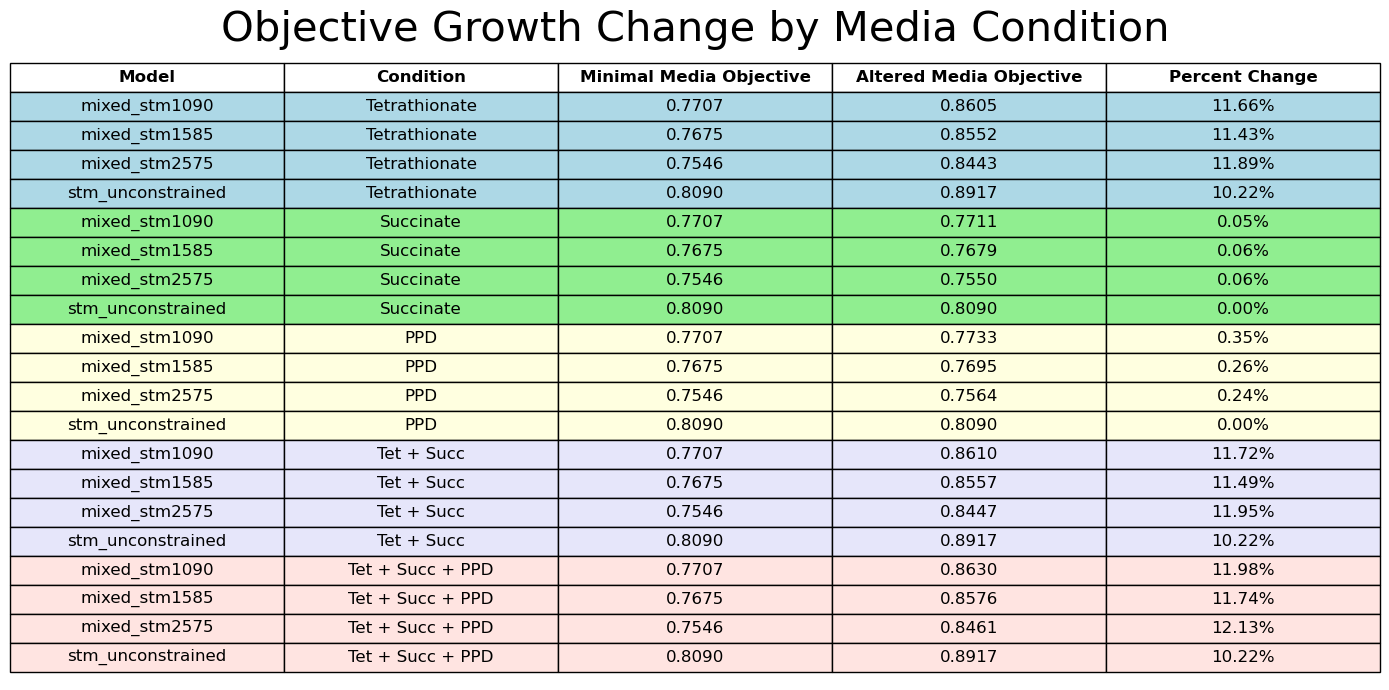

In [10]:
# save table as an image

import matplotlib.pyplot as plt

plot_dir = f"/home/gmvaz/2026_GEMs/stm_model_test/plots"

# Sort conditions in desired order
condition_order = [
    "Tetrathionate",
    "Succinate",
    "PPD",
    "Tet + Succ",
    "Tet + Succ + PPD"
]

objective_table_df = (
    objective_change_df
    .with_columns(
        pl.col("Condition")
        .replace_strict(
            condition_order,
            list(range(len(condition_order)))
        )
        .alias("condition_order")
    )
    .sort(["condition_order", "Model"])
    .drop("condition_order")
)

# Colors for each condition
condition_colors = {
    "Tetrathionate": "lightblue",
    "Succinate": "lightgreen",
    "PPD": "lightyellow",
    "Tet + Succ": "lavender",
    "Tet + Succ + PPD": "mistyrose"
}

# Column names
columns = objective_table_df.columns

# Format table values
cell_text = []

for row in objective_table_df.iter_rows(named=True):

    cell_text.append([
        row["Model"],
        row["Condition"],
        f'{row["Minimal Media Objective"]:.4f}',
        f'{row["Altered Media Objective"]:.4f}',
        f'{row["Percent Change"]:.2f}%'
    ])

# Assign row colors by condition
cell_colors = []

for row in objective_table_df.iter_rows(named=True):

    color = condition_colors[row["Condition"]]

    cell_colors.append(
        [color] * len(columns)
    )

# Create table
fig, ax = plt.subplots(figsize=(14, 7))

ax.axis("off")

table = ax.table(
    cellText=cell_text,
    colLabels=columns,
    cellColours=cell_colors,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

# Format table
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1, 1.5)

# Format header
for col in range(len(columns)):
    table[(0, col)].set_text_props(weight="bold")

plt.title(
    "Objective Growth Change by Media Condition",
    fontsize=30,
    pad=10
)

plt.tight_layout()

# Save image
plt.savefig(
    f"{plot_dir}/objective_growth_change_table.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Plot Percent Change in Growth Rate

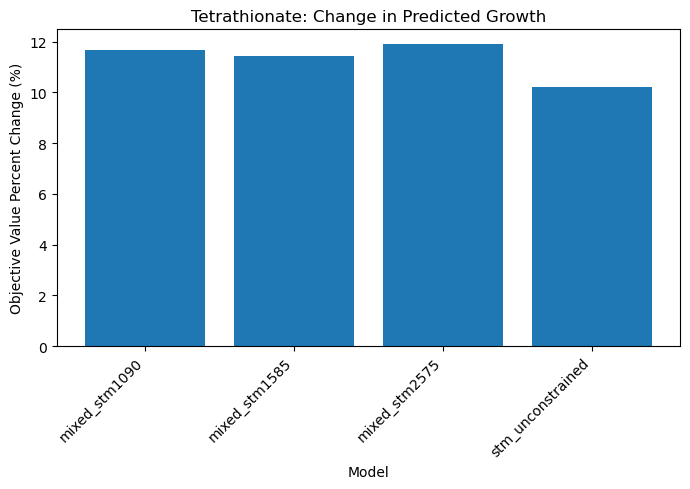

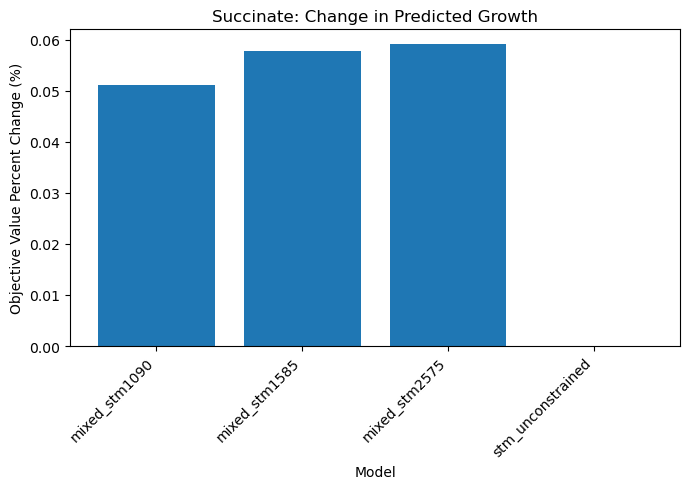

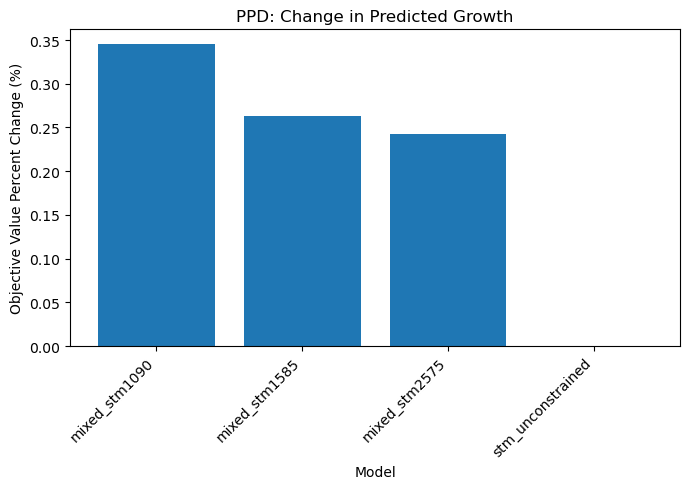

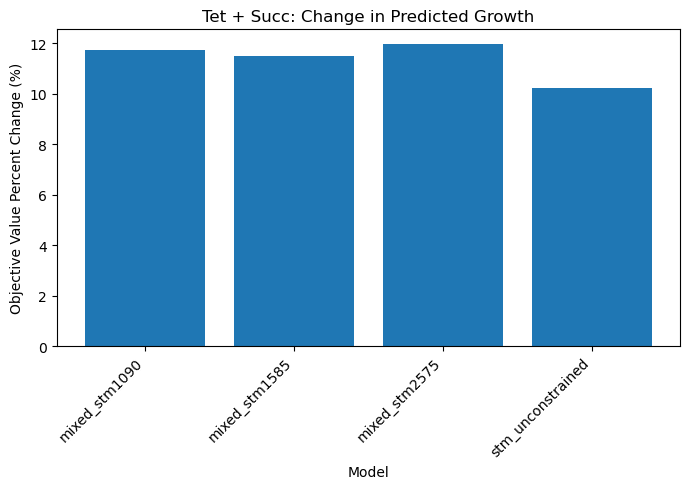

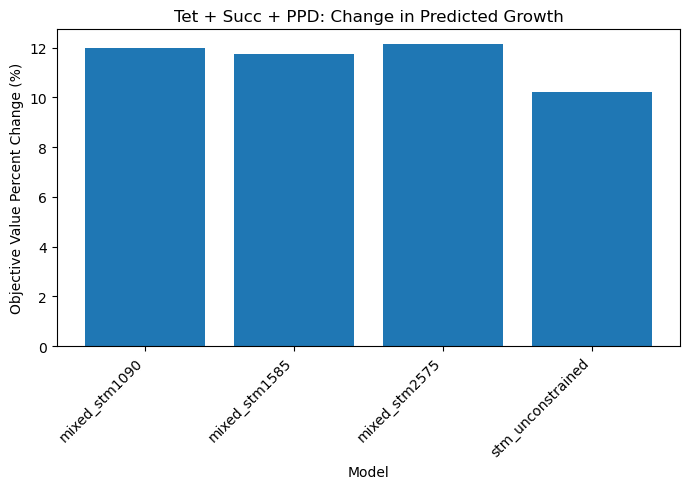

In [11]:
plot_dir = f"/home/gmvaz/2026_GEMs/stm_model_test/plots"

condition_order = [
    "Tetrathionate",
    "Succinate",
    "PPD",
    "Tet + Succ",
    "Tet + Succ + PPD"
]

for condition in condition_order:

    condition_df = objective_change_df.filter(
        pl.col("Condition") == condition
    )

    plt.figure(figsize=(7, 5))

    plt.bar(
        condition_df["Model"].to_list(),
        condition_df["Percent Change"].to_list()
    )

    plt.ylabel("Objective Value Percent Change (%)")
    plt.xlabel("Model")
    plt.title(f"{condition}: Change in Predicted Growth")

    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()

    file_name = condition.lower().replace(" ", "_").replace("+", "and")

    plt.savefig(
        f"{plot_dir}/{file_name}_growth_percent_change.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

## Uptake of Added Metabolites to the Medium

In [12]:
added_metabolite_flux_df = (
    flux_df

    # Get filename
    .with_columns(
        pl.col("filename")
        .str.extract(r"([^/]+)$", 1)
        .alias("file")
    )

    # Identify condition
    .with_columns(
        pl.when(pl.col("file").str.contains("_tet_succ_ppd_minimal_media_"))
        .then(pl.lit("Tet + Succ + PPD"))

        .when(pl.col("file").str.contains("_tet_and_succ_minimal_media_"))
        .then(pl.lit("Tet + Succ"))

        .when(pl.col("file").str.contains("_tet_minimal_media_"))
        .then(pl.lit("Tetrathionate"))

        .when(pl.col("file").str.contains("_succ_minimal_media_"))
        .then(pl.lit("Succinate"))

        .when(pl.col("file").str.contains("_ppd_minimal_media_"))
        .then(pl.lit("PPD"))

        .otherwise(pl.lit("Minimal Media"))
        .alias("Condition")
    )

    # Identify model
    .with_columns(
        pl.col("file")
        .str.replace(
            r"_(tet_succ_ppd|tet_and_succ|tet|succ|ppd)_minimal_media_solution_flux\.csv$",
            ""
        )
        .str.replace(
            r"_minimal_media_solution_flux\.csv$",
            ""
        )
        .alias("Model")
    )

    # Keep only metabolites added in each condition
    .filter(
        ((pl.col("Condition") == "Tetrathionate") &
         (pl.col("Reaction") == "EX_tet_e"))

        |

        ((pl.col("Condition") == "Succinate") &
         (pl.col("Reaction") == "EX_succ_e"))

        |

        ((pl.col("Condition") == "PPD") &
         pl.col("Reaction").is_in([
             "EX_12ppd__R_e",
             "EX_12ppd__S_e"
         ]))

        |

        ((pl.col("Condition") == "Tet + Succ") &
         pl.col("Reaction").is_in([
             "EX_tet_e",
             "EX_succ_e"
         ]))

        |

        ((pl.col("Condition") == "Tet + Succ + PPD") &
         pl.col("Reaction").is_in([
             "EX_tet_e",
             "EX_succ_e",
             "EX_12ppd__R_e",
             "EX_12ppd__S_e"
         ]))
    )

    # Add metabolite name and medium uptake bound
    .with_columns(
        pl.when(pl.col("Reaction") == "EX_tet_e")
        .then(pl.lit("Tetrathionate"))

        .when(pl.col("Reaction") == "EX_succ_e")
        .then(pl.lit("Succinate"))

        .when(pl.col("Reaction") == "EX_12ppd__R_e")
        .then(pl.lit("1,2-Propanediol R"))

        .when(pl.col("Reaction") == "EX_12ppd__S_e")
        .then(pl.lit("1,2-Propanediol S"))

        .alias("Added Metabolite"),

        pl.when(pl.col("Reaction") == "EX_tet_e")
        .then(pl.lit(4.0))

        .when(pl.col("Reaction") == "EX_succ_e")
        .then(pl.lit(3.0))

        .when(pl.col("Reaction").is_in([
            "EX_12ppd__R_e",
            "EX_12ppd__S_e"
        ]))
        .then(pl.lit(0.1))

        .alias("Medium Uptake Bound")
    )

    # Separate raw exchange flux into uptake and secretion
    .with_columns(
        pl.when(pl.col("Flux") < 0)
        .then(-pl.col("Flux"))
        .otherwise(0)
        .alias("Uptake Flux"),

        pl.when(pl.col("Flux") > 0)
        .then(pl.col("Flux"))
        .otherwise(0)
        .alias("Secretion Flux")
    )

    .select(
        "Model",
        "Condition",
        "Added Metabolite",
        "Reaction",
        "Reaction Name",
        "Medium Uptake Bound",
        "Uptake Flux",
        "Secretion Flux"
    )

    .sort([
        "Condition",
        "Added Metabolite",
        "Model"
    ])
)

added_metabolite_flux_df

Model,Condition,Added Metabolite,Reaction,Reaction Name,Medium Uptake Bound,Uptake Flux,Secretion Flux
str,str,str,str,str,f64,f64,f64
"""mixed_stm1090""","""PPD""","""1,2-Propanediol R""","""EX_12ppd__R_e""","""(R)-Propane-1,2-diol exchange""",0.1,0.0,0.01
"""mixed_stm1585""","""PPD""","""1,2-Propanediol R""","""EX_12ppd__R_e""","""(R)-Propane-1,2-diol exchange""",0.1,0.0,0.01
"""mixed_stm2575""","""PPD""","""1,2-Propanediol R""","""EX_12ppd__R_e""","""(R)-Propane-1,2-diol exchange""",0.1,0.01,0.0
"""stm_unconstrained""","""PPD""","""1,2-Propanediol R""","""EX_12ppd__R_e""","""(R)-Propane-1,2-diol exchange""",0.1,0.1,0.0
"""mixed_stm1090""","""PPD""","""1,2-Propanediol S""","""EX_12ppd__S_e""","""(S)-Propane-1,2-diol exchange""",0.1,0.1,0.0
…,…,…,…,…,…,…,…
"""stm_unconstrained""","""Tet + Succ + PPD""","""Tetrathionate""","""EX_tet_e""","""Tetrathionate exchange""",4.0,4.0,0.0
"""mixed_stm1090""","""Tetrathionate""","""Tetrathionate""","""EX_tet_e""","""Tetrathionate exchange""",4.0,4.0,0.0
"""mixed_stm1585""","""Tetrathionate""","""Tetrathionate""","""EX_tet_e""","""Tetrathionate exchange""",4.0,4.0,0.0


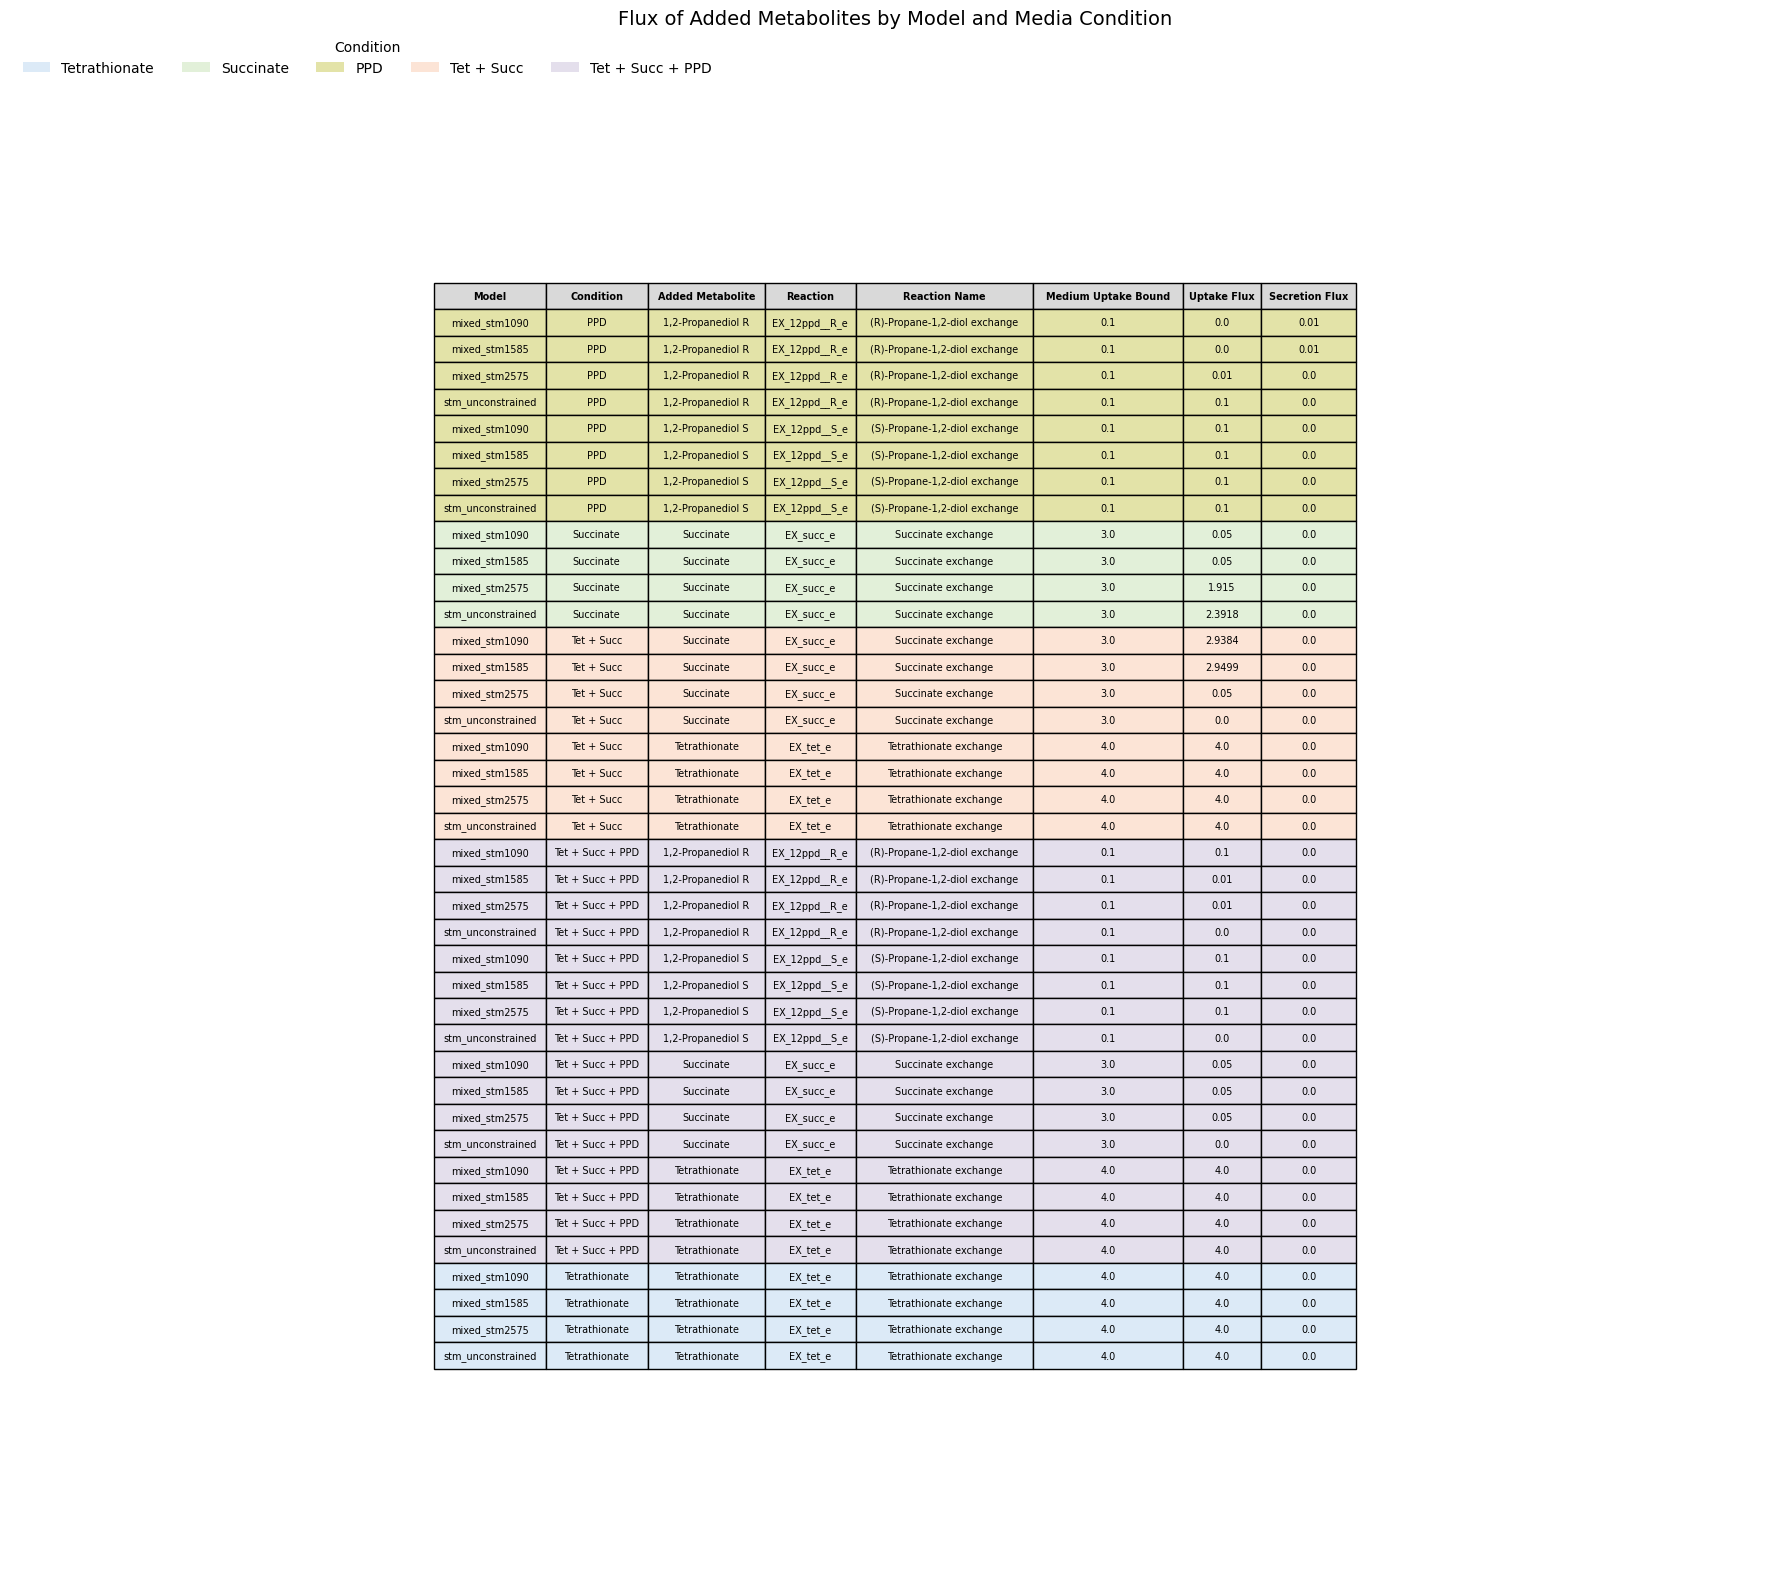

In [13]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Folder for saved table
plot_dir = f"/home/gmvaz/2026_GEMs/stm_model_test/plots"

# Colors for each media condition
condition_colors = {
    "Tetrathionate": "#DCEAF7",
    "Succinate": "#E2F0D9",
    "PPD": "#E3E3A8",
    "Tet + Succ": "#FCE4D6",
    "Tet + Succ + PPD": "#E4DFEC"
}

# Make a display copy and round numeric columns
table_df = added_metabolite_flux_df.with_columns(
    pl.col("Medium Uptake Bound").round(3),
    pl.col("Uptake Flux").round(4),
    pl.col("Secretion Flux").round(4)
)

# Table contents
cell_text = table_df.rows()
column_labels = table_df.columns

# Color each row according to condition
row_colors = [
    condition_colors[condition]
    for condition in table_df["Condition"].to_list()
]

cell_colors = [
    [color] * len(column_labels)
    for color in row_colors
]

# Create figure
fig, ax = plt.subplots(figsize=(18, 16))
ax.axis("off")

table = ax.table(
    cellText=cell_text,
    colLabels=column_labels,
    cellColours=cell_colors,
    colColours=["#D9D9D9"] * len(column_labels),
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(7)
table.scale(1, 1.3)

# Bold column headers
for col in range(len(column_labels)):
    table[(0, col)].set_text_props(weight="bold")

# Automatically adjust column widths
table.auto_set_column_width(
    col=list(range(len(column_labels)))
)

# Legend
legend_handles = [
    Patch(facecolor=color, label=condition)
    for condition, color in condition_colors.items()
]

ax.legend(
    handles=legend_handles,
    title="Condition",
    loc="upper left",
    bbox_to_anchor=(0, 1.03),
    ncol=5,
    frameon=False
)

plt.title(
    "Flux of Added Metabolites by Model and Media Condition",
    fontsize=14,
    pad=35
)

plt.tight_layout()

plt.savefig(
    f"{plot_dir}/added_metabolite_flux_df.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

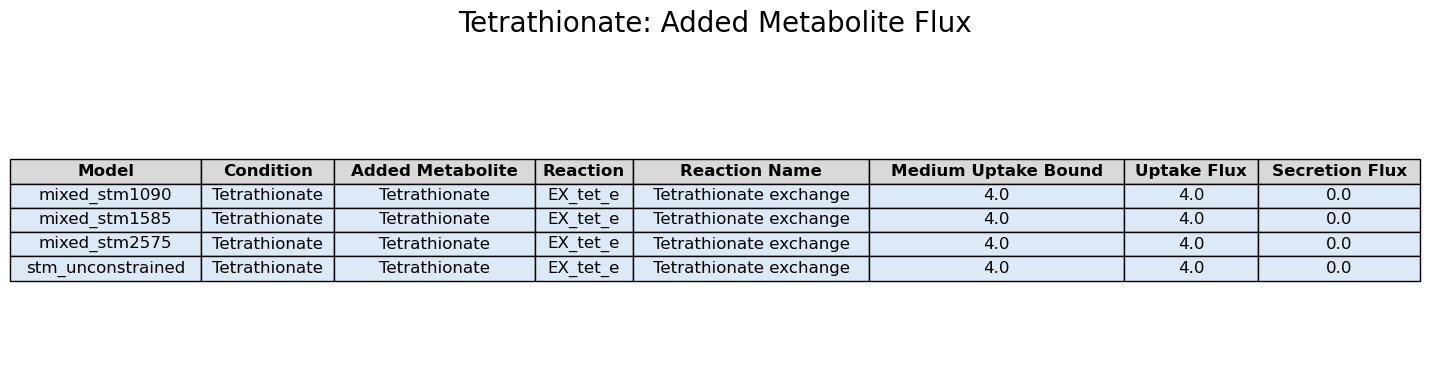

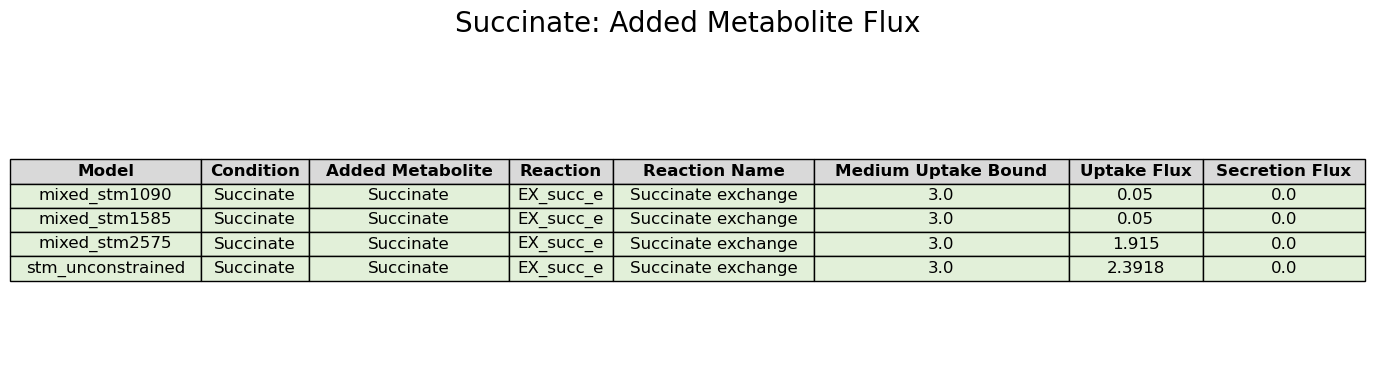

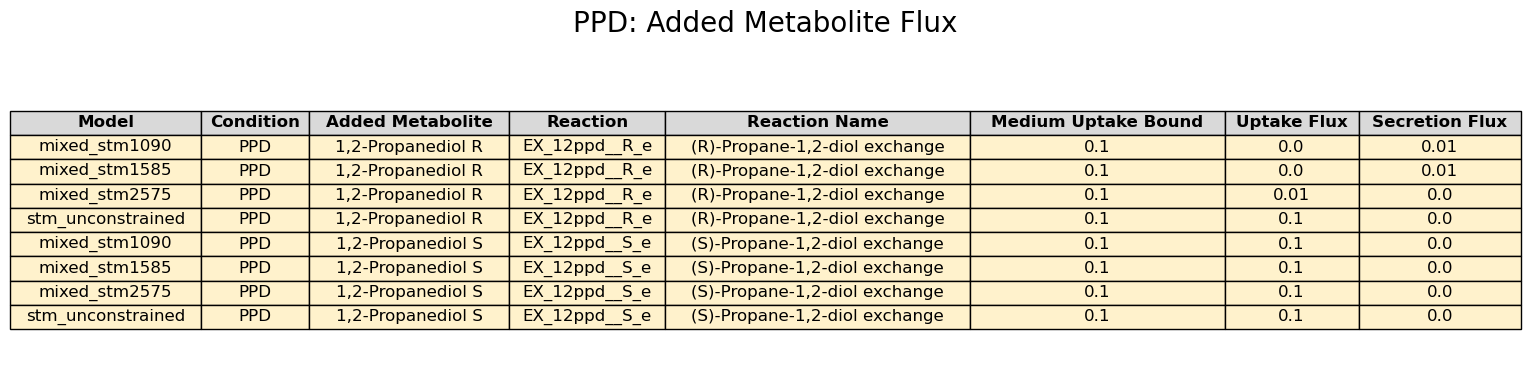

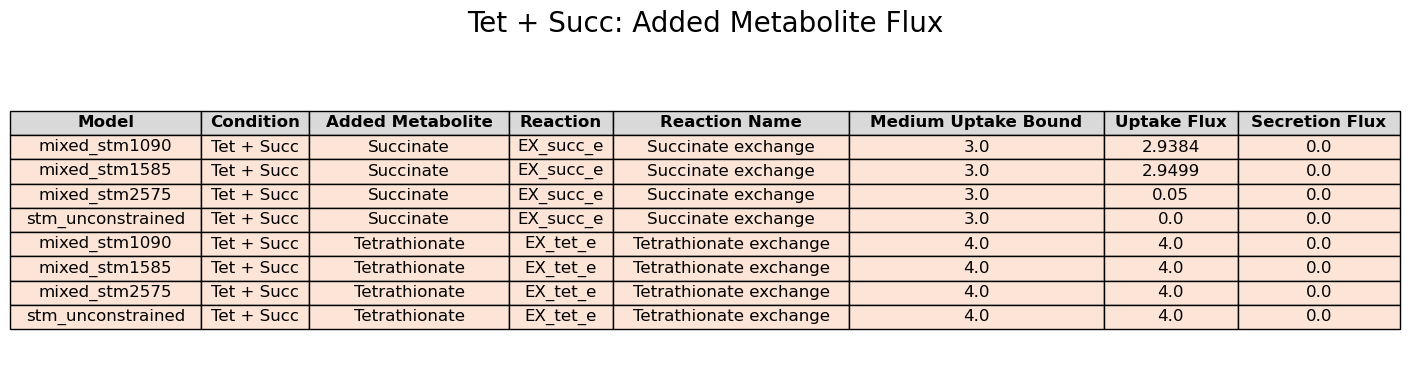

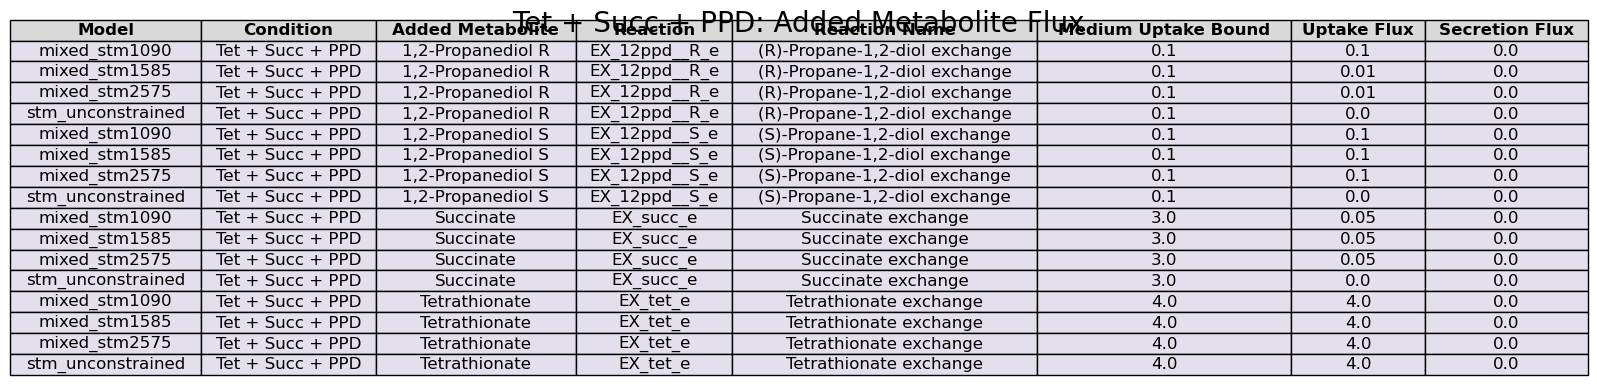

In [14]:
condition_order = [
    "Tetrathionate",
    "Succinate",
    "PPD",
    "Tet + Succ",
    "Tet + Succ + PPD"
]

condition_colors = {
    "Tetrathionate": "#DCEAF7",
    "Succinate": "#E2F0D9",
    "PPD": "#FFF2CC",
    "Tet + Succ": "#FCE4D6",
    "Tet + Succ + PPD": "#E4DFEC"
}

for condition in condition_order:

    condition_df = (
        added_metabolite_flux_df
        .filter(pl.col("Condition") == condition)
        .with_columns(
            pl.col("Medium Uptake Bound").round(3),
            pl.col("Uptake Flux").round(4),
            pl.col("Secretion Flux").round(4)
        )
    )

    cell_text = condition_df.rows()
    column_labels = condition_df.columns

    fig, ax = plt.subplots(figsize=(14, 4))
    ax.axis("off")

    table = ax.table(
        cellText=cell_text,
        colLabels=column_labels,
        cellLoc="center",
        loc="center",
        colColours=["#D9D9D9"] * len(column_labels)
    )

    table.auto_set_font_size(False)
    table.set_fontsize(12)
    table.scale(1, 1.4)

    # Color all data rows according to condition
    for row in range(1, len(cell_text) + 1):
        for col in range(len(column_labels)):
            table[(row, col)].set_facecolor(
                condition_colors[condition]
            )

    # Bold headers
    for col in range(len(column_labels)):
        table[(0, col)].set_text_props(weight="bold")

    table.auto_set_column_width(
        col=list(range(len(column_labels)))
    )

    plt.title(
        f"{condition}: Added Metabolite Flux",
        fontsize=20,
        pad=20
    )

    plt.tight_layout()

    file_name = (
        condition.lower()
        .replace(" ", "_")
        .replace("+", "and")
    )

    plt.savefig(
        f"{plot_dir}/{file_name}_added_metabolite_flux_table.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

## Comparing added metabolite utilization across conditions

In [15]:
uptake_comparison_df = (
    added_metabolite_flux_df

    .select(
        "Model",
        "Added Metabolite",
        "Condition",
        "Medium Uptake Bound",
        "Uptake Flux"
    )

    .sort([
        "Added Metabolite",
        "Model",
        "Condition"
    ])
)

uptake_comparison_df

Model,Added Metabolite,Condition,Medium Uptake Bound,Uptake Flux
str,str,str,f64,f64
"""mixed_stm1090""","""1,2-Propanediol R""","""PPD""",0.1,0.0
"""mixed_stm1090""","""1,2-Propanediol R""","""Tet + Succ + PPD""",0.1,0.1
"""mixed_stm1585""","""1,2-Propanediol R""","""PPD""",0.1,0.0
"""mixed_stm1585""","""1,2-Propanediol R""","""Tet + Succ + PPD""",0.1,0.01
"""mixed_stm2575""","""1,2-Propanediol R""","""PPD""",0.1,0.01
…,…,…,…,…
"""mixed_stm2575""","""Tetrathionate""","""Tet + Succ + PPD""",4.0,4.0
"""mixed_stm2575""","""Tetrathionate""","""Tetrathionate""",4.0,4.0
"""stm_unconstrained""","""Tetrathionate""","""Tet + Succ""",4.0,4.0


In [16]:
uptake_comparison_wide_df = (
    uptake_comparison_df

    .pivot(
        on="Condition",
        index=[
            "Model",
            "Added Metabolite"
        ],
        values="Uptake Flux",
        aggregate_function="first"
    )

    .sort([
        "Added Metabolite",
        "Model"
    ])
)

uptake_comparison_wide_df

Model,Added Metabolite,PPD,Tet + Succ + PPD,Succinate,Tet + Succ,Tetrathionate
str,str,f64,f64,f64,f64,f64
"""mixed_stm1090""","""1,2-Propanediol R""",0.0,0.1,null,null,null
"""mixed_stm1585""","""1,2-Propanediol R""",0.0,0.01,null,null,null
"""mixed_stm2575""","""1,2-Propanediol R""",0.01,0.01,null,null,null
"""stm_unconstrained""","""1,2-Propanediol R""",0.1,0.0,null,null,null
"""mixed_stm1090""","""1,2-Propanediol S""",0.1,0.1,null,null,null
…,…,…,…,…,…,…
"""stm_unconstrained""","""Succinate""",null,0.0,2.391792,0.0,null
"""mixed_stm1090""","""Tetrathionate""",null,4.0,null,4.0,4.0
"""mixed_stm1585""","""Tetrathionate""",null,4.0,null,4.0,4.0


In [17]:
uptake_comparison_df = (
    added_metabolite_flux_df

    .with_columns(
        (
            pl.col("Uptake Flux")
            / pl.col("Medium Uptake Bound")
            * 100
        ).alias("Percent of Uptake Bound Used")
    )

    .select(
        "Model",
        "Added Metabolite",
        "Condition",
        "Medium Uptake Bound",
        "Uptake Flux",
        "Percent of Uptake Bound Used"
    )

    .sort([
        "Added Metabolite",
        "Model",
        "Condition"
    ])
)

uptake_comparison_df

Model,Added Metabolite,Condition,Medium Uptake Bound,Uptake Flux,Percent of Uptake Bound Used
str,str,str,f64,f64,f64
"""mixed_stm1090""","""1,2-Propanediol R""","""PPD""",0.1,0.0,0.0
"""mixed_stm1090""","""1,2-Propanediol R""","""Tet + Succ + PPD""",0.1,0.1,100.0
"""mixed_stm1585""","""1,2-Propanediol R""","""PPD""",0.1,0.0,0.0
"""mixed_stm1585""","""1,2-Propanediol R""","""Tet + Succ + PPD""",0.1,0.01,10.0
"""mixed_stm2575""","""1,2-Propanediol R""","""PPD""",0.1,0.01,10.0
…,…,…,…,…,…
"""mixed_stm2575""","""Tetrathionate""","""Tet + Succ + PPD""",4.0,4.0,100.0
"""mixed_stm2575""","""Tetrathionate""","""Tetrathionate""",4.0,4.0,100.0
"""stm_unconstrained""","""Tetrathionate""","""Tet + Succ""",4.0,4.0,100.0


In [18]:
with pl.Config(tbl_rows=-1, tbl_cols=-1):
    print(uptake_comparison_df)

shape: (40, 6)
┌────────────────┬────────────────┬────────────────┬────────────────┬─────────────┬────────────────┐
│ Model          ┆ Added          ┆ Condition      ┆ Medium Uptake  ┆ Uptake Flux ┆ Percent of     │
│ ---            ┆ Metabolite     ┆ ---            ┆ Bound          ┆ ---         ┆ Uptake Bound   │
│ str            ┆ ---            ┆ str            ┆ ---            ┆ f64         ┆ Used           │
│                ┆ str            ┆                ┆ f64            ┆             ┆ ---            │
│                ┆                ┆                ┆                ┆             ┆ f64            │
╞════════════════╪════════════════╪════════════════╪════════════════╪═════════════╪════════════════╡
│ mixed_stm1090  ┆ 1,2-Propanedio ┆ PPD            ┆ 0.1            ┆ 0.0         ┆ 0.0            │
│                ┆ l R            ┆                ┆                ┆             ┆                │
│ mixed_stm1090  ┆ 1,2-Propanedio ┆ Tet + Succ +   ┆ 0.1            ┆ 0.1   

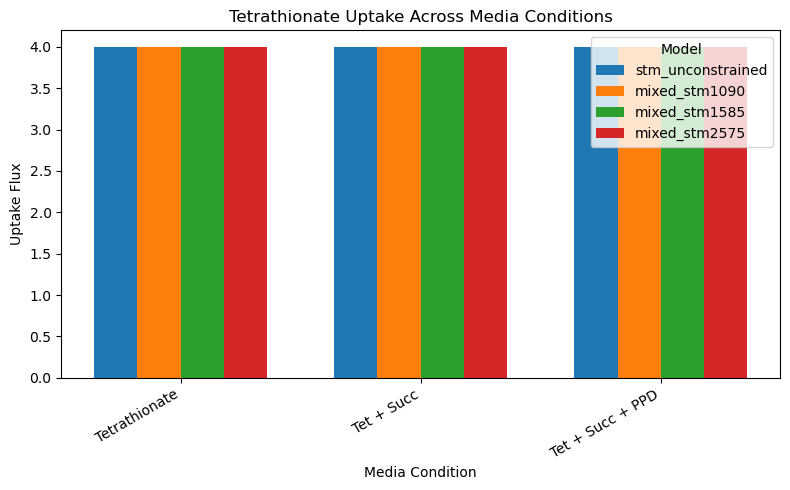

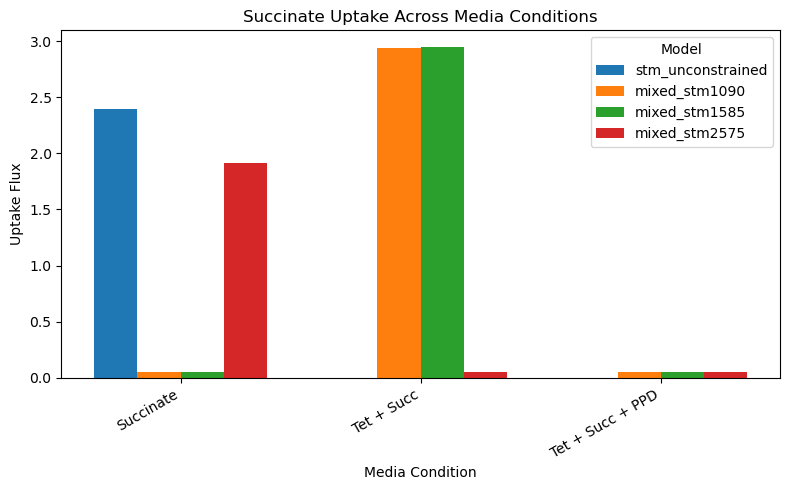

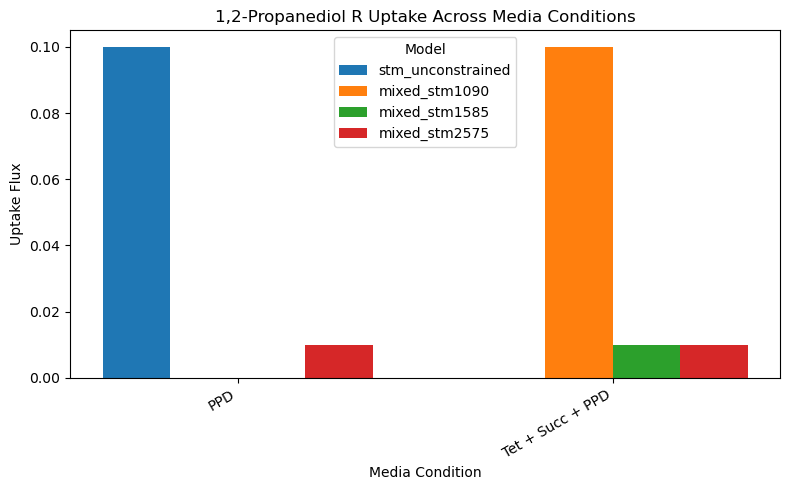

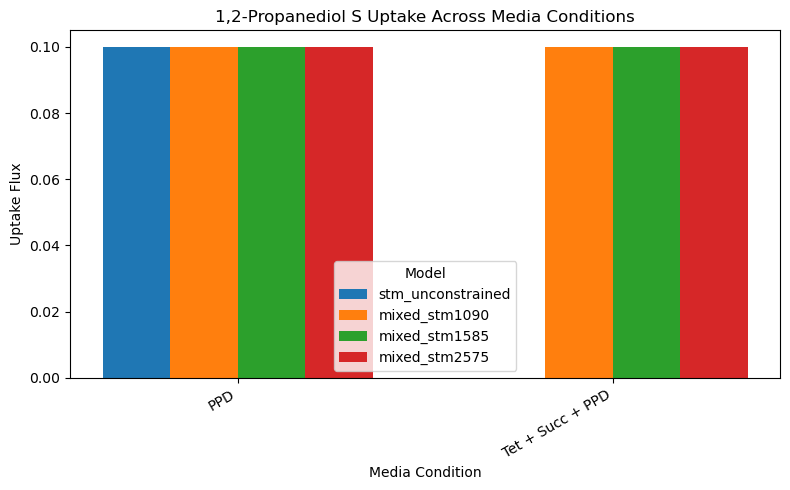

In [19]:
import numpy as np
import matplotlib.pyplot as plt

metabolites = [
    "Tetrathionate",
    "Succinate",
    "1,2-Propanediol R",
    "1,2-Propanediol S"
]

models = [
    "stm_unconstrained",
    "mixed_stm1090",
    "mixed_stm1585",
    "mixed_stm2575"
]

condition_order = {
    "Tetrathionate": [
        "Tetrathionate",
        "Tet + Succ",
        "Tet + Succ + PPD"
    ],
    "Succinate": [
        "Succinate",
        "Tet + Succ",
        "Tet + Succ + PPD"
    ],
    "1,2-Propanediol R": [
        "PPD",
        "Tet + Succ + PPD"
    ],
    "1,2-Propanediol S": [
        "PPD",
        "Tet + Succ + PPD"
    ]
}

for metabolite in metabolites:

    metabolite_df = uptake_comparison_df.filter(
        pl.col("Added Metabolite") == metabolite
    )

    conditions = condition_order[metabolite]

    x = np.arange(len(conditions))
    width = 0.18

    plt.figure(figsize=(8, 5))

    for i, model in enumerate(models):

        model_df = metabolite_df.filter(
            pl.col("Model") == model
        )

        uptake_values = []

        for condition in conditions:

            value = (
                model_df
                .filter(pl.col("Condition") == condition)
                ["Uptake Flux"]
                .to_list()
            )

            uptake_values.append(value[0] if value else 0)

        plt.bar(
            x + (i - 1.5) * width,
            uptake_values,
            width,
            label=model
        )

    plt.xticks(
        x,
        conditions,
        rotation=30,
        ha="right"
    )

    plt.ylabel("Uptake Flux")
    plt.xlabel("Media Condition")
    plt.title(f"{metabolite} Uptake Across Media Conditions")

    plt.legend(title="Model")
    plt.tight_layout()

    plt.show()

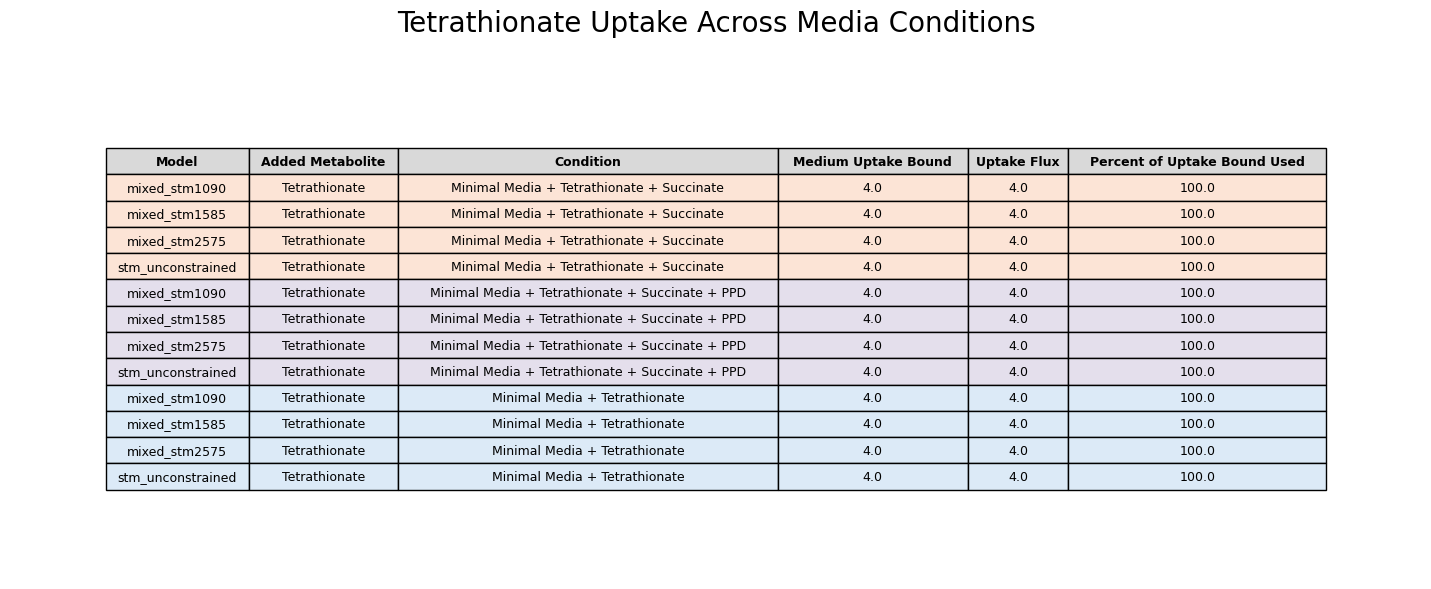

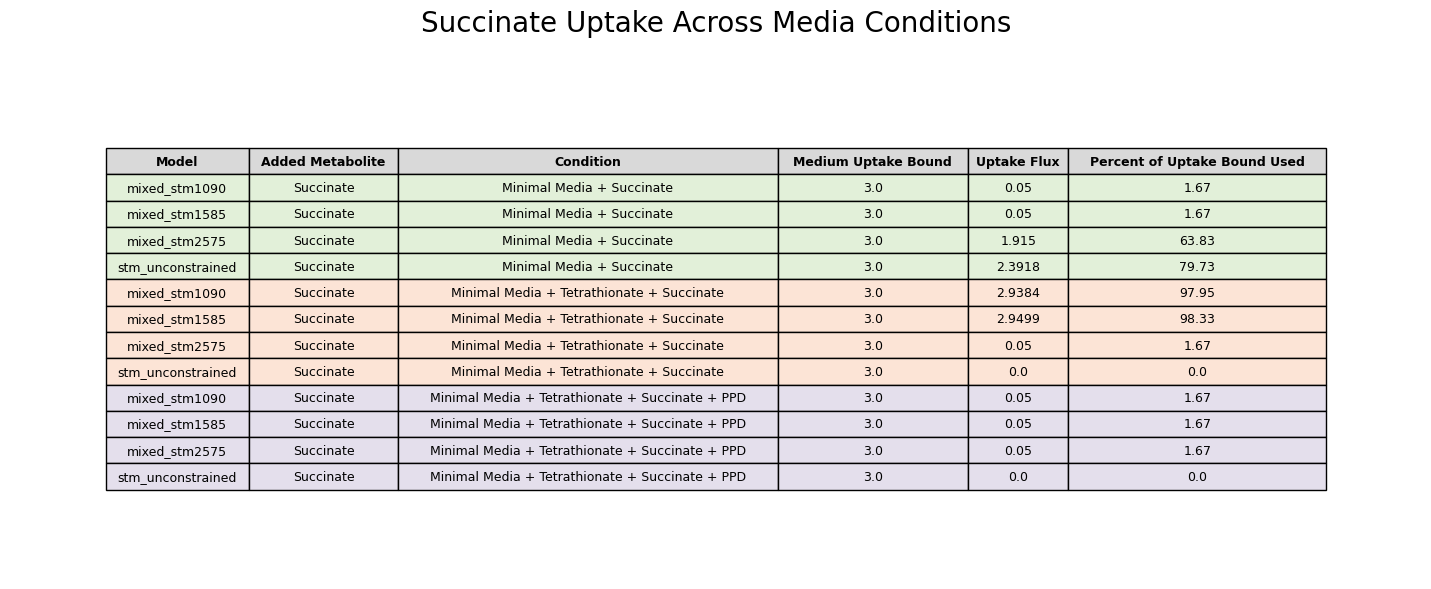

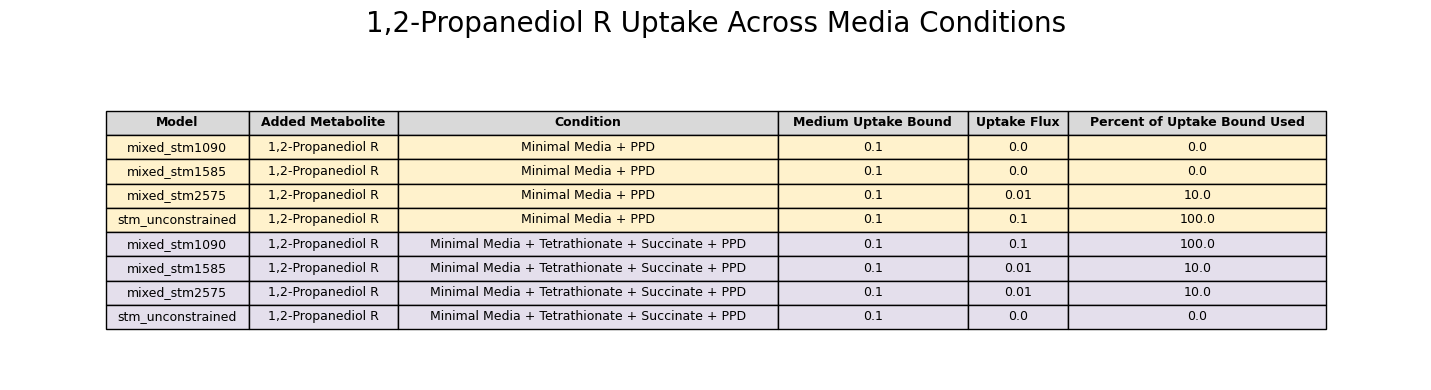

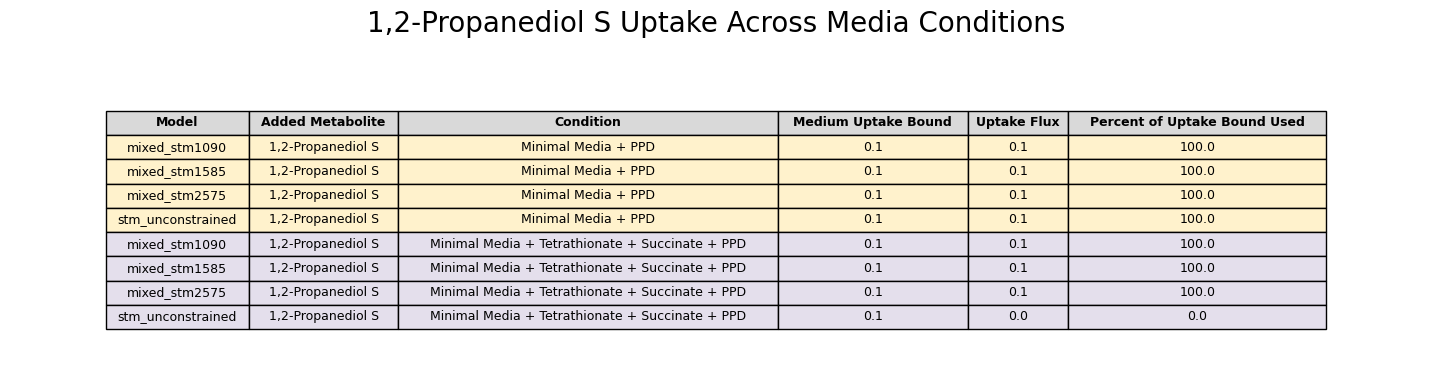

In [20]:
condition_descriptions = {
    "Tetrathionate": "Minimal Media + Tetrathionate",
    "Succinate": "Minimal Media + Succinate",
    "PPD": "Minimal Media + PPD",
    "Tet + Succ": "Minimal Media + Tetrathionate + Succinate",
    "Tet + Succ + PPD": "Minimal Media + Tetrathionate + Succinate + PPD"
}

condition_colors = {
    "Tetrathionate": "#DCEAF7",
    "Succinate": "#E2F0D9",
    "PPD": "#FFF2CC",
    "Tet + Succ": "#FCE4D6",
    "Tet + Succ + PPD": "#E4DFEC"
}

metabolites = [
    "Tetrathionate",
    "Succinate",
    "1,2-Propanediol R",
    "1,2-Propanediol S"
]

for metabolite in metabolites:

    metabolite_df = (
        uptake_comparison_df
        .filter(pl.col("Added Metabolite") == metabolite)
        .sort(["Condition", "Model"])
    )

    # Save original condition values for coloring
    conditions = metabolite_df["Condition"].to_list()

    # Replace condition names with full media descriptions
    metabolite_df = metabolite_df.with_columns(
        pl.col("Condition")
        .replace(condition_descriptions)
        .alias("Condition"),

        pl.col("Medium Uptake Bound").round(3),
        pl.col("Uptake Flux").round(4),
        pl.col("Percent of Uptake Bound Used").round(2)
    )

    cell_text = metabolite_df.rows()
    column_labels = metabolite_df.columns

    fig_height = max(4, len(cell_text) * 0.5)

    fig, ax = plt.subplots(figsize=(15, fig_height))
    ax.axis("off")

    table = ax.table(
        cellText=cell_text,
        colLabels=column_labels,
        cellLoc="center",
        loc="center",
        colColours=["#D9D9D9"] * len(column_labels)
    )

    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1, 1.4)

    # Color each row according to media condition
    for row, condition in enumerate(conditions, start=1):
        for col in range(len(column_labels)):
            table[(row, col)].set_facecolor(
                condition_colors[condition]
            )

    # Bold headers
    for col in range(len(column_labels)):
        table[(0, col)].set_text_props(weight="bold")

    table.auto_set_column_width(
        col=list(range(len(column_labels)))
    )

    plt.title(
        f"{metabolite} Uptake Across Media Conditions",
        fontsize=20,
        pad=20
    )

    plt.tight_layout()

    file_name = (
        metabolite.lower()
        .replace(" ", "_")
        .replace(",", "")
        .replace("-", "_")
    )

    plt.savefig(
        f"{plot_dir}/{file_name}_uptake_comparison_table.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

## Plots for HMI presentation 09/30/26

In [36]:
model_labels = {
    "stm_unconstrained": "S. Tm Unconstrained",
    "mixed_stm1090": "S. Tm Constrained 10%",
    "mixed_stm1585": "S. Tm Constrained 15%",
    "mixed_stm2575": "S. Tm Constrained 25%"
}

# Calculate objective change directly from growth_df
objective_change_viz_df = (
    growth_df

    .filter(
        pl.col("Condition") != "Minimal Media"
    )

    .select(
        "Model",
        "Condition",
        pl.col("Objective Value").alias("Altered Media Objective")
    )

    .join(
        minimal_growth,
        on="Model",
        how="left"
    )

    .with_columns(
        (
            (
                pl.col("Altered Media Objective")
                - pl.col("Minimal Media Objective")
            )
            / pl.col("Minimal Media Objective")
            * 100
        ).alias("Objective Percent Change")
    )
)


# Combine objective change with metabolite utilization
viz_df = (
    objective_change_viz_df

    .join(
        uptake_comparison_df.select(
            "Model",
            "Condition",
            "Added Metabolite",
            "Medium Uptake Bound",
            "Uptake Flux",
            "Percent of Uptake Bound Used"
        ),
        on=["Model", "Condition"],
        how="left"
    )

    .with_columns(
        pl.col("Model")
        .replace(model_labels)
        .alias("Model")
    )

    .select(
        "Model",
        "Condition",
        "Added Metabolite",
        "Minimal Media Objective",
        "Altered Media Objective",
        "Objective Percent Change",
        "Medium Uptake Bound",
        "Uptake Flux",
        "Percent of Uptake Bound Used"
    )

    .sort([
        "Condition",
        "Added Metabolite",
        "Model"
    ])
)

viz_df

Model,Condition,Added Metabolite,Minimal Media Objective,Altered Media Objective,Objective Percent Change,Medium Uptake Bound,Uptake Flux,Percent of Uptake Bound Used
str,str,str,f64,f64,f64,f64,f64,f64
"""S. Tm Constrained 10%""","""PPD""","""1,2-Propanediol R""",0.770684,0.773343,0.345026,0.1,0.0,0.0
"""S. Tm Constrained 15%""","""PPD""","""1,2-Propanediol R""",0.767465,0.769488,0.263579,0.1,0.0,0.0
"""S. Tm Constrained 25%""","""PPD""","""1,2-Propanediol R""",0.754592,0.756425,0.242898,0.1,0.01,10.0
"""S. Tm Unconstrained""","""PPD""","""1,2-Propanediol R""",0.809029,0.809029,2.1957e-13,0.1,0.1,100.0
"""S. Tm Constrained 10%""","""PPD""","""1,2-Propanediol S""",0.770684,0.773343,0.345026,0.1,0.1,100.0
…,…,…,…,…,…,…,…,…
"""S. Tm Unconstrained""","""Tet + Succ + PPD""","""Tetrathionate""",0.809029,0.891746,10.224252,4.0,4.0,100.0
"""S. Tm Constrained 10%""","""Tetrathionate""","""Tetrathionate""",0.770684,0.860537,11.658856,4.0,4.0,100.0
"""S. Tm Constrained 15%""","""Tetrathionate""","""Tetrathionate""",0.767465,0.855216,11.433839,4.0,4.0,100.0


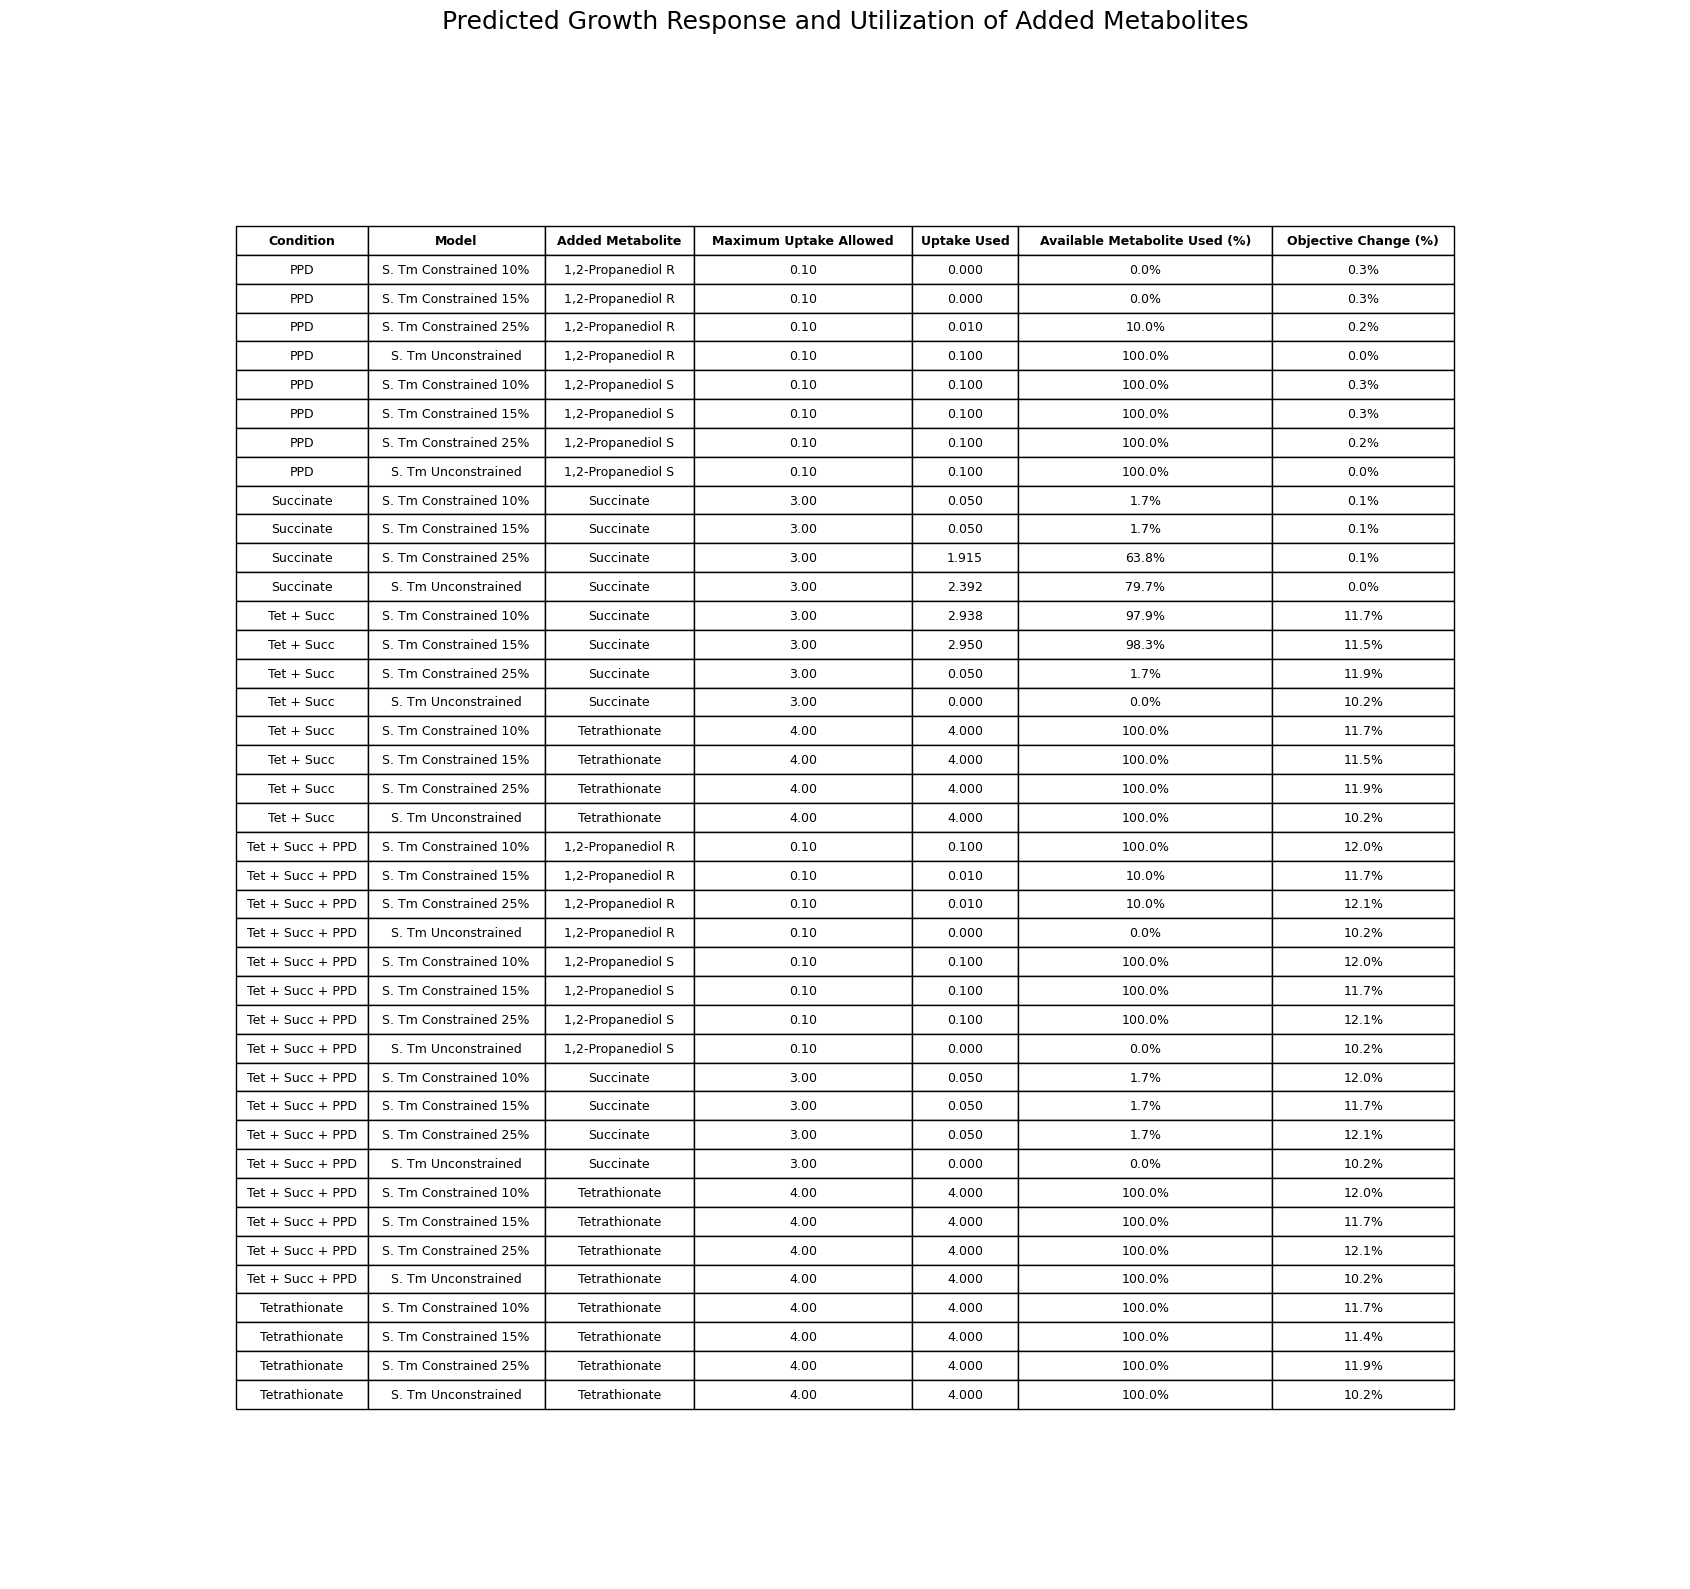

In [29]:
import matplotlib.pyplot as plt


plot_dir = "/home/gmvaz/2026_GEMs/stm_model_test/plots"


# Column names that are easier to interpret in a figure
option1_df = (
    viz_df

    .select(
        "Condition",
        "Model",
        "Added Metabolite",
        "Medium Uptake Bound",
        "Uptake Flux",
        "Percent of Uptake Bound Used",
        "Objective Percent Change"
    )

    .with_columns(
        pl.col("Medium Uptake Bound").round(2),
        pl.col("Uptake Flux").round(3),
        pl.col("Percent of Uptake Bound Used").round(1),
        pl.col("Objective Percent Change").round(1)
    )

    .rename({
        "Medium Uptake Bound": "Maximum Uptake Allowed",
        "Uptake Flux": "Uptake Used",
        "Percent of Uptake Bound Used": "Available Metabolite Used (%)",
        "Objective Percent Change": "Objective Change (%)"
    })
)


# Convert values to formatted text
cell_text = []

for row in option1_df.iter_rows(named=True):

    cell_text.append([
        row["Condition"],
        row["Model"],
        row["Added Metabolite"],
        f'{row["Maximum Uptake Allowed"]:.2f}',
        f'{row["Uptake Used"]:.3f}',
        f'{row["Available Metabolite Used (%)"]:.1f}%',
        f'{row["Objective Change (%)"]:.1f}%'
    ])


column_labels = option1_df.columns


# Make table
fig_height = max(
    6,
    len(cell_text) * 0.40
)

fig, ax = plt.subplots(
    figsize=(17, fig_height)
)

ax.axis("off")

table = ax.table(
    cellText=cell_text,
    colLabels=column_labels,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.4)


# Header formatting
for col in range(len(column_labels)):
    table[(0, col)].set_text_props(
        weight="bold"
    )


table.auto_set_column_width(
    col=list(range(len(column_labels)))
)


plt.title(
    "Predicted Growth Response and Utilization of Added Metabolites",
    fontsize=18,
    pad=20
)

plt.tight_layout()

plt.savefig(
    f"{plot_dir}/growth_and_metabolite_utilization_table.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

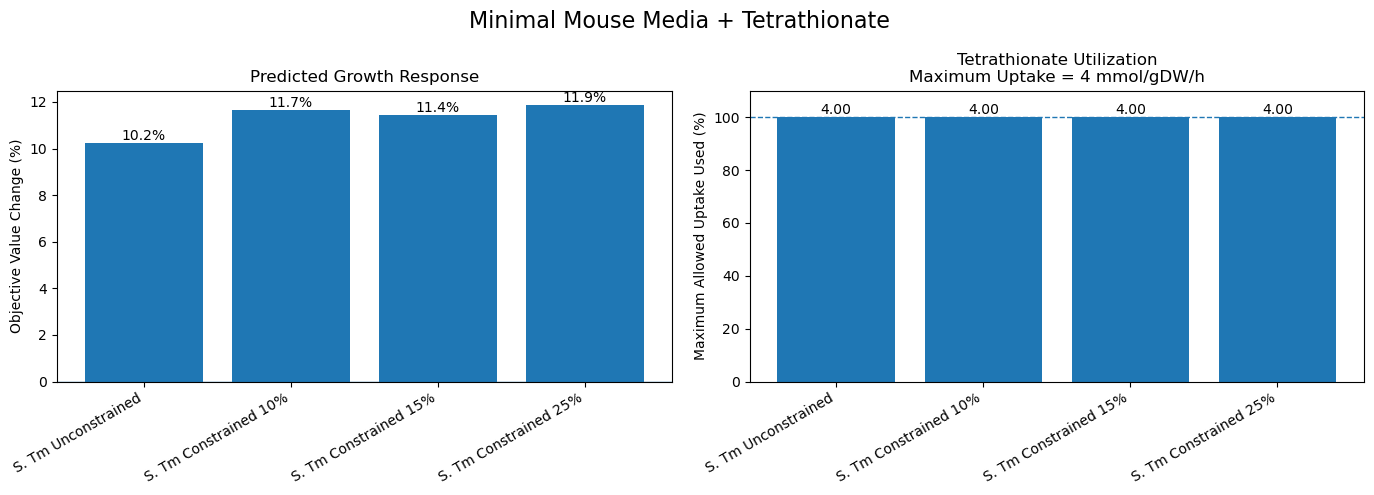

In [38]:
model_order = [
    "S. Tm Unconstrained",
    "S. Tm Constrained 10%",
    "S. Tm Constrained 15%",
    "S. Tm Constrained 25%"
]

# ============================================================
# TETRATHIONATE
# ============================================================

condition = "Tetrathionate"

condition_df = (
    viz_df
    .filter(pl.col("Condition") == condition)
)

# ------------------------------------------------------------
# Growth response
# ------------------------------------------------------------

growth_df_plot = (
    condition_df
    .select(
        "Model",
        "Objective Percent Change"
    )
    .unique()
)

growth_lookup = {
    row["Model"]: row["Objective Percent Change"]
    for row in growth_df_plot.iter_rows(named=True)
}

models_present = [
    model for model in model_order
    if model in growth_lookup
]

growth_values = [
    growth_lookup[model]
    for model in models_present
]


# ------------------------------------------------------------
# Tetrathionate utilization
# ------------------------------------------------------------

tet_df = (
    condition_df
    .filter(
        pl.col("Added Metabolite") == "Tetrathionate"
    )
)

tet_lookup = {
    row["Model"]: row
    for row in tet_df.iter_rows(named=True)
}

tet_percent = [
    tet_lookup[model]["Percent of Uptake Bound Used"]
    for model in models_present
]

tet_flux = [
    tet_lookup[model]["Uptake Flux"]
    for model in models_present
]

tet_bound = tet_df["Medium Uptake Bound"][0]


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

x = np.arange(len(models_present))

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)


# Growth plot

bars = axes[0].bar(
    x,
    growth_values
)

axes[0].axhline(
    0,
    linewidth=1
)

axes[0].set_xticks(x)

axes[0].set_xticklabels(
    models_present,
    rotation=30,
    ha="right"
)

axes[0].set_ylabel(
    "Objective Value Change (%)"
)

axes[0].set_title(
    "Predicted Growth Response"
)

for bar, value in zip(
    bars,
    growth_values
):

    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.1f}%",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )


# Tetrathionate utilization plot

bars = axes[1].bar(
    x,
    tet_percent
)

axes[1].axhline(
    100,
    linestyle="--",
    linewidth=1
)

axes[1].set_xticks(x)

axes[1].set_xticklabels(
    models_present,
    rotation=30,
    ha="right"
)

axes[1].set_ylabel(
    "Maximum Allowed Uptake Used (%)"
)

axes[1].set_ylim(
    0,
    110
)

axes[1].set_title(
    f"Tetrathionate Utilization\n"
    f"Maximum Uptake = {tet_bound:g} mmol/gDW/h"
)

for bar, percent, flux in zip(
    bars,
    tet_percent,
    tet_flux
):

    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        percent,
        f"{flux:.2f}",
        ha="center",
        va="bottom"
    )


fig.suptitle(
    "Minimal Mouse Media + Tetrathionate",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    f"{plot_dir}/tetrathionate_growth_and_utilization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

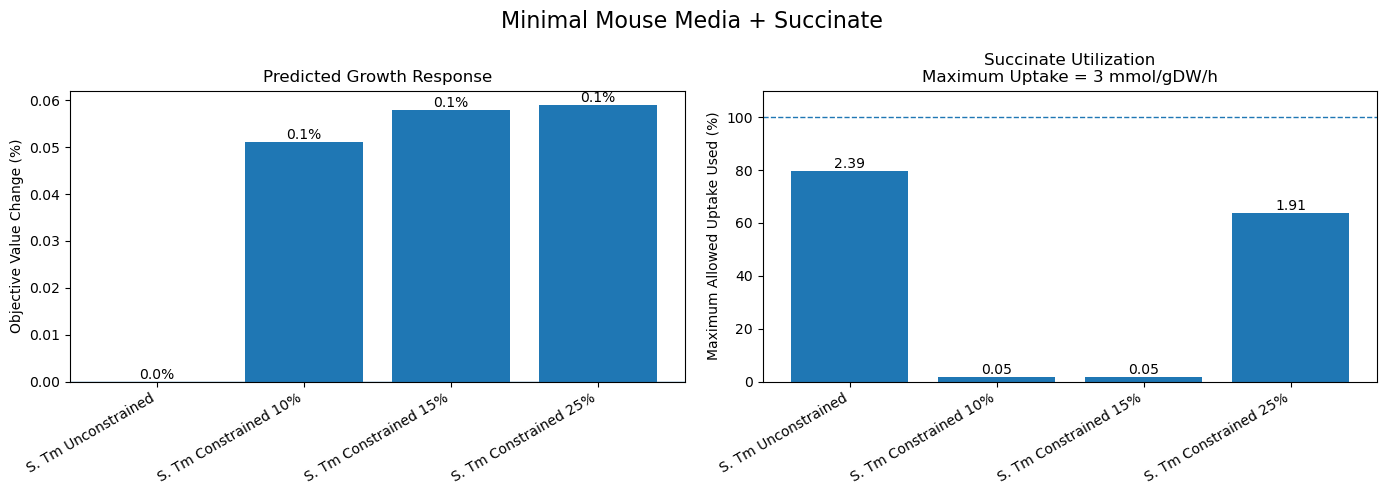

In [39]:
# ============================================================
# SUCCINATE
# ============================================================

condition = "Succinate"

condition_df = (
    viz_df
    .filter(pl.col("Condition") == condition)
)


# ------------------------------------------------------------
# Growth response
# ------------------------------------------------------------

growth_df_plot = (
    condition_df
    .select(
        "Model",
        "Objective Percent Change"
    )
    .unique()
)

growth_lookup = {
    row["Model"]: row["Objective Percent Change"]
    for row in growth_df_plot.iter_rows(named=True)
}

models_present = [
    model for model in model_order
    if model in growth_lookup
]

growth_values = [
    growth_lookup[model]
    for model in models_present
]


# ------------------------------------------------------------
# Succinate utilization
# ------------------------------------------------------------

succ_df = (
    condition_df
    .filter(
        pl.col("Added Metabolite") == "Succinate"
    )
)

succ_lookup = {
    row["Model"]: row
    for row in succ_df.iter_rows(named=True)
}

succ_percent = [
    succ_lookup[model]["Percent of Uptake Bound Used"]
    for model in models_present
]

succ_flux = [
    succ_lookup[model]["Uptake Flux"]
    for model in models_present
]

succ_bound = succ_df["Medium Uptake Bound"][0]


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

x = np.arange(len(models_present))

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)


# Growth

bars = axes[0].bar(
    x,
    growth_values
)

axes[0].axhline(
    0,
    linewidth=1
)

axes[0].set_xticks(x)

axes[0].set_xticklabels(
    models_present,
    rotation=30,
    ha="right"
)

axes[0].set_ylabel(
    "Objective Value Change (%)"
)

axes[0].set_title(
    "Predicted Growth Response"
)

for bar, value in zip(
    bars,
    growth_values
):

    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.1f}%",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )


# Succinate utilization

bars = axes[1].bar(
    x,
    succ_percent
)

axes[1].axhline(
    100,
    linestyle="--",
    linewidth=1
)

axes[1].set_xticks(x)

axes[1].set_xticklabels(
    models_present,
    rotation=30,
    ha="right"
)

axes[1].set_ylabel(
    "Maximum Allowed Uptake Used (%)"
)

axes[1].set_ylim(
    0,
    110
)

axes[1].set_title(
    f"Succinate Utilization\n"
    f"Maximum Uptake = {succ_bound:g} mmol/gDW/h"
)

for bar, percent, flux in zip(
    bars,
    succ_percent,
    succ_flux
):

    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        percent,
        f"{flux:.2f}",
        ha="center",
        va="bottom"
    )


fig.suptitle(
    "Minimal Mouse Media + Succinate",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    f"{plot_dir}/succinate_growth_and_utilization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

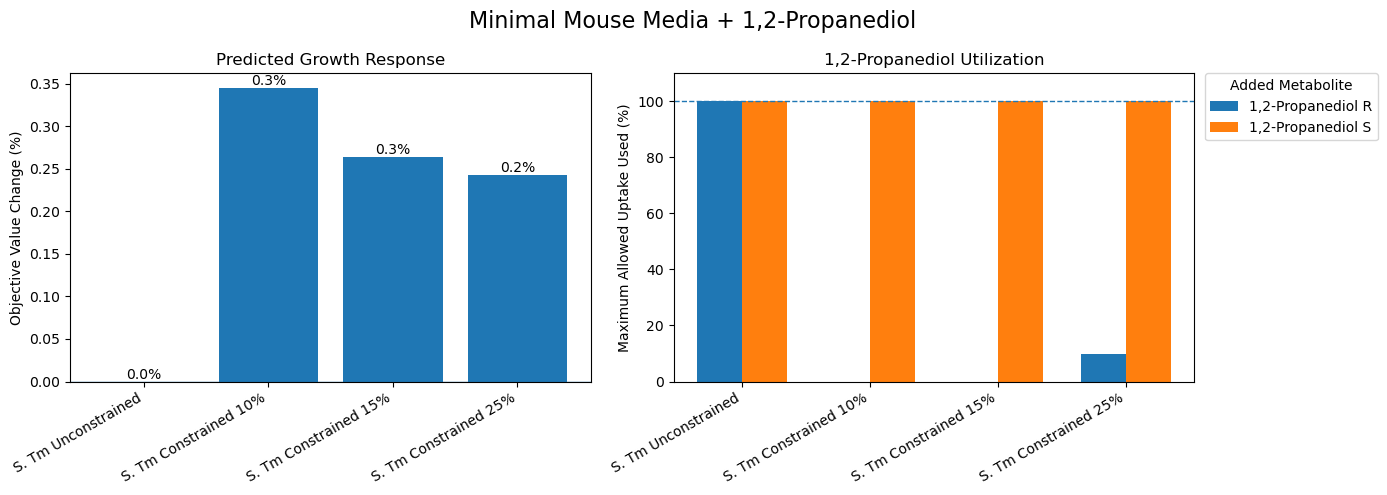

In [53]:
# Actual uptake amount for each model
ppd_r_flux = [
    ppd_r_lookup[model]["Uptake Flux"]
    for model in models_present
]

ppd_s_flux = [
    ppd_s_lookup[model]["Uptake Flux"]
    for model in models_present
]

# Maximum uptake allowed in the medium
ppd_r_bound = ppd_r_df["Medium Uptake Bound"][0]
ppd_s_bound = ppd_s_df["Medium Uptake Bound"][0]

# ============================================================
# PPD
# ============================================================

condition = "PPD"

condition_df = (
    viz_df
    .filter(pl.col("Condition") == condition)
)


# ------------------------------------------------------------
# Growth response
# ------------------------------------------------------------

growth_df_plot = (
    condition_df
    .select(
        "Model",
        "Objective Percent Change"
    )
    .unique()
)

growth_lookup = {
    row["Model"]: row["Objective Percent Change"]
    for row in growth_df_plot.iter_rows(named=True)
}

models_present = [
    model for model in model_order
    if model in growth_lookup
]

growth_values = [
    growth_lookup[model]
    for model in models_present
]


# ------------------------------------------------------------
# PPD R
# ------------------------------------------------------------

ppd_r_df = (
    condition_df
    .filter(
        pl.col("Added Metabolite") == "1,2-Propanediol R"
    )
)

ppd_r_lookup = {
    row["Model"]: row
    for row in ppd_r_df.iter_rows(named=True)
}

ppd_r_percent = [
    ppd_r_lookup[model]["Percent of Uptake Bound Used"]
    for model in models_present
]


# ------------------------------------------------------------
# PPD S
# ------------------------------------------------------------

ppd_s_df = (
    condition_df
    .filter(
        pl.col("Added Metabolite") == "1,2-Propanediol S"
    )
)

ppd_s_lookup = {
    row["Model"]: row
    for row in ppd_s_df.iter_rows(named=True)
}

ppd_s_percent = [
    ppd_s_lookup[model]["Percent of Uptake Bound Used"]
    for model in models_present
]


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

x = np.arange(len(models_present))
width = 0.35

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)


# Growth

bars = axes[0].bar(
    x,
    growth_values
)

axes[0].axhline(
    0,
    linewidth=1
)

axes[0].set_xticks(x)

axes[0].set_xticklabels(
    models_present,
    rotation=30,
    ha="right"
)

axes[0].set_ylabel(
    "Objective Value Change (%)"
)

axes[0].set_title(
    "Predicted Growth Response"
)

for bar, value in zip(
    bars,
    growth_values
):

    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.1f}%",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )


# PPD utilization

axes[1].bar(
    x - width / 2,
    ppd_r_percent,
    width,
    label="1,2-Propanediol R"
)

axes[1].bar(
    x + width / 2,
    ppd_s_percent,
    width,
    label="1,2-Propanediol S"
)

axes[1].axhline(
    100,
    linestyle="--",
    linewidth=1
)

axes[1].set_xticks(x)

axes[1].set_xticklabels(
    models_present,
    rotation=30,
    ha="right"
)

axes[1].set_ylabel(
    "Maximum Allowed Uptake Used (%)"
)

axes[1].set_ylim(
    0,
    110
)

axes[1].set_title(
    "1,2-Propanediol Utilization"
)

axes[1].legend(
    title="Added Metabolite",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0
)


fig.suptitle(
    "Minimal Mouse Media + 1,2-Propanediol",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    f"{plot_dir}/ppd_growth_and_utilization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

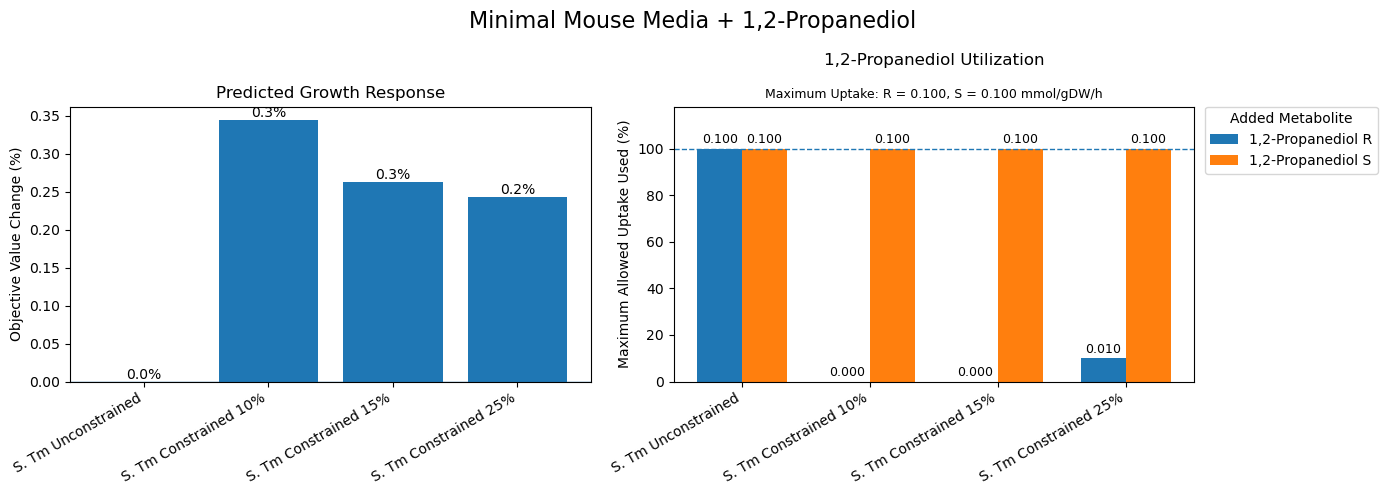

In [64]:
# ============================================================
# PPD
# ============================================================

condition = "PPD"

condition_df = (
    viz_df
    .filter(
        pl.col("Condition") == condition
    )
)


# ============================================================
# GROWTH RESPONSE
# ============================================================

growth_df_plot = (
    condition_df
    .select(
        "Model",
        "Objective Percent Change"
    )
    .unique()
)


# Make dictionary:
# model -> objective percent change
growth_lookup = {
    row["Model"]: row["Objective Percent Change"]
    for row in growth_df_plot.iter_rows(named=True)
}


# Keep models in desired order
models_present = [
    model
    for model in model_order
    if model in growth_lookup
]


# Objective percent change for each model
growth_values = [
    growth_lookup[model]
    for model in models_present
]


# ============================================================
# PPD R UTILIZATION
# ============================================================

ppd_r_df = (
    condition_df
    .filter(
        pl.col("Added Metabolite")
        == "1,2-Propanediol R"
    )
)


# Make dictionary:
# model -> row of PPD-R results
ppd_r_lookup = {
    row["Model"]: row
    for row in ppd_r_df.iter_rows(named=True)
}


# Percent of maximum uptake used
ppd_r_percent = [
    ppd_r_lookup[model]["Percent of Uptake Bound Used"]
    for model in models_present
]


# Actual amount taken up
ppd_r_flux = [
    ppd_r_lookup[model]["Uptake Flux"]
    for model in models_present
]


# Maximum uptake allowed in the medium
ppd_r_bound = (
    ppd_r_df["Medium Uptake Bound"][0]
)


# ============================================================
# PPD S UTILIZATION
# ============================================================

ppd_s_df = (
    condition_df
    .filter(
        pl.col("Added Metabolite")
        == "1,2-Propanediol S"
    )
)


# Make dictionary:
# model -> row of PPD-S results
ppd_s_lookup = {
    row["Model"]: row
    for row in ppd_s_df.iter_rows(named=True)
}


# Percent of maximum uptake used
ppd_s_percent = [
    ppd_s_lookup[model]["Percent of Uptake Bound Used"]
    for model in models_present
]


# Actual amount taken up
ppd_s_flux = [
    ppd_s_lookup[model]["Uptake Flux"]
    for model in models_present
]


# Maximum uptake allowed in the medium
ppd_s_bound = (
    ppd_s_df["Medium Uptake Bound"][0]
)


# ============================================================
# PLOT
# ============================================================

x = np.arange(
    len(models_present)
)

width = 0.35


fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)


# ============================================================
# LEFT: GROWTH RESPONSE
# ============================================================

growth_bars = axes[0].bar(
    x,
    growth_values
)


axes[0].axhline(
    0,
    linewidth=1
)


axes[0].set_xticks(x)


axes[0].set_xticklabels(
    models_present,
    rotation=30,
    ha="right"
)


axes[0].set_ylabel(
    "Objective Value Change (%)"
)


axes[0].set_title(
    "Predicted Growth Response"
)


# Report objective percent change above each bar
for bar, value in zip(
    growth_bars,
    growth_values
):

    axes[0].text(
        bar.get_x()
        + bar.get_width() / 2,

        value,

        f"{value:.1f}%",

        ha="center",

        va=(
            "bottom"
            if value >= 0
            else "top"
        )
    )


# ============================================================
# RIGHT: PPD UTILIZATION
# ============================================================

# Bar height = percent of maximum uptake used
ppd_r_bars = axes[1].bar(
    x - width / 2,
    ppd_r_percent,
    width,
    label="1,2-Propanediol R"
)


ppd_s_bars = axes[1].bar(
    x + width / 2,
    ppd_s_percent,
    width,
    label="1,2-Propanediol S"
)


# 100% = entire available uptake bound used
axes[1].axhline(
    100,
    linestyle="--",
    linewidth=1
)


axes[1].set_xticks(x)


axes[1].set_xticklabels(
    models_present,
    rotation=30,
    ha="right"
)


axes[1].set_ylabel(
    "Maximum Allowed Uptake Used (%)"
)


# Give enough room above 100% bars
# for the uptake-flux labels
axes[1].set_ylim(
    0,
    118
)


# Main title
axes[1].set_title(
    "1,2-Propanediol Utilization",
    pad=30
)


# Maximum uptake displayed under title
axes[1].text(
    0.5,
    1.02,

    (
        f"Maximum Uptake: "
        f"R = {ppd_r_bound:.3f}, "
        f"S = {ppd_s_bound:.3f} mmol/gDW/h"
    ),

    transform=axes[1].transAxes,

    ha="center",
    va="bottom",

    fontsize=9
)


# ============================================================
# ACTUAL PPD-R UPTAKE ABOVE EACH BAR
# ============================================================

for bar, percent, flux in zip(
    ppd_r_bars,
    ppd_r_percent,
    ppd_r_flux
):

    axes[1].text(
        bar.get_x()
        + bar.get_width() / 2,

        percent + 1,

        f"{flux:.3f}",

        ha="center",
        va="bottom",

        fontsize=9
    )


# ============================================================
# ACTUAL PPD-S UPTAKE ABOVE EACH BAR
# ============================================================

for bar, percent, flux in zip(
    ppd_s_bars,
    ppd_s_percent,
    ppd_s_flux
):

    axes[1].text(
        bar.get_x()
        + bar.get_width() / 2,

        percent + 1,

        f"{flux:.3f}",

        ha="center",
        va="bottom",

        fontsize=9
    )


# Legend outside plot
axes[1].legend(
    title="Added Metabolite",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0
)


# ============================================================
# FIGURE TITLE
# ============================================================

fig.suptitle(
    "Minimal Mouse Media + 1,2-Propanediol",
    fontsize=16
)


plt.tight_layout()


plt.savefig(
    f"{plot_dir}/ppd_growth_and_utilization.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

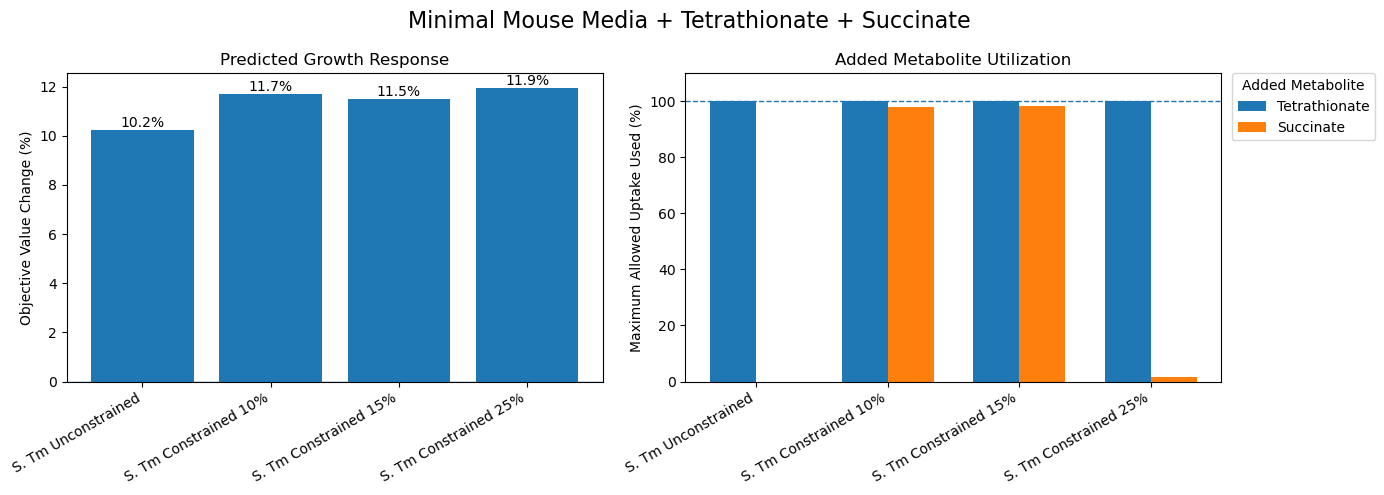

In [65]:
# ============================================================
# TETRATHIONATE + SUCCINATE
# ============================================================

condition = "Tet + Succ"

condition_df = (
    viz_df
    .filter(pl.col("Condition") == condition)
)


# Growth
growth_df_plot = (
    condition_df
    .select(
        "Model",
        "Objective Percent Change"
    )
    .unique()
)

growth_lookup = {
    row["Model"]: row["Objective Percent Change"]
    for row in growth_df_plot.iter_rows(named=True)
}

models_present = [
    model for model in model_order
    if model in growth_lookup
]

growth_values = [
    growth_lookup[model]
    for model in models_present
]


# Tetrathionate
tet_df = condition_df.filter(
    pl.col("Added Metabolite") == "Tetrathionate"
)

tet_lookup = {
    row["Model"]: row
    for row in tet_df.iter_rows(named=True)
}

tet_percent = [
    tet_lookup[model]["Percent of Uptake Bound Used"]
    for model in models_present
]


# Succinate
succ_df = condition_df.filter(
    pl.col("Added Metabolite") == "Succinate"
)

succ_lookup = {
    row["Model"]: row
    for row in succ_df.iter_rows(named=True)
}

succ_percent = [
    succ_lookup[model]["Percent of Uptake Bound Used"]
    for model in models_present
]


# Plot
x = np.arange(len(models_present))
width = 0.35

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)


# Growth
bars = axes[0].bar(
    x,
    growth_values
)

axes[0].axhline(0, linewidth=1)

axes[0].set_xticks(x)

axes[0].set_xticklabels(
    models_present,
    rotation=30,
    ha="right"
)

axes[0].set_ylabel(
    "Objective Value Change (%)"
)

axes[0].set_title(
    "Predicted Growth Response"
)

for bar, value in zip(
    bars,
    growth_values
):

    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.1f}%",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )


# Utilization
axes[1].bar(
    x - width / 2,
    tet_percent,
    width,
    label="Tetrathionate"
)

axes[1].bar(
    x + width / 2,
    succ_percent,
    width,
    label="Succinate"
)

axes[1].axhline(
    100,
    linestyle="--",
    linewidth=1
)

axes[1].set_xticks(x)

axes[1].set_xticklabels(
    models_present,
    rotation=30,
    ha="right"
)

axes[1].set_ylabel(
    "Maximum Allowed Uptake Used (%)"
)

axes[1].set_ylim(
    0,
    110
)

axes[1].set_title(
    "Added Metabolite Utilization"
)

axes[1].legend(
    title="Added Metabolite",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0
)


fig.suptitle(
    "Minimal Mouse Media + Tetrathionate + Succinate",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    f"{plot_dir}/tet_and_succ_growth_and_utilization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

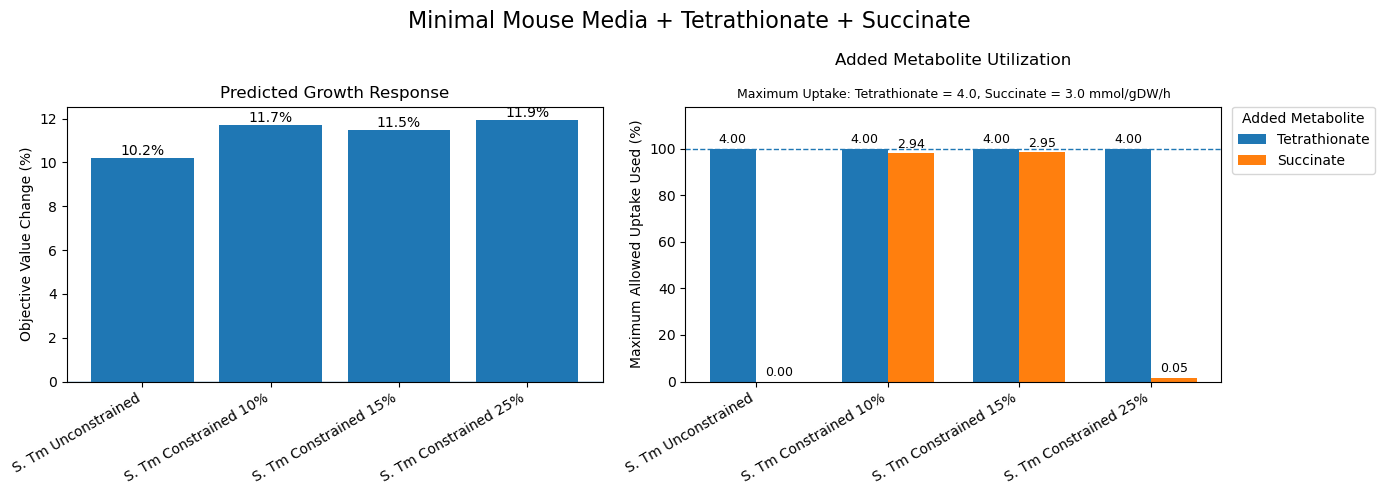

In [58]:
# ============================================================
# TETRATHIONATE + SUCCINATE
# ============================================================

condition = "Tet + Succ"

condition_df = (
    viz_df
    .filter(pl.col("Condition") == condition)
)


# ============================================================
# GROWTH RESPONSE
# ============================================================

growth_df_plot = (
    condition_df
    .select(
        "Model",
        "Objective Percent Change"
    )
    .unique()
)

growth_lookup = {
    row["Model"]: row["Objective Percent Change"]
    for row in growth_df_plot.iter_rows(named=True)
}

models_present = [
    model for model in model_order
    if model in growth_lookup
]

growth_values = [
    growth_lookup[model]
    for model in models_present
]


# ============================================================
# TETRATHIONATE
# ============================================================

tet_df = (
    condition_df
    .filter(
        pl.col("Added Metabolite") == "Tetrathionate"
    )
)

tet_lookup = {
    row["Model"]: row
    for row in tet_df.iter_rows(named=True)
}


# Percent of maximum tetrathionate uptake used
tet_percent = [
    tet_lookup[model]["Percent of Uptake Bound Used"]
    for model in models_present
]


# Actual tetrathionate uptake utilized
tet_flux = [
    tet_lookup[model]["Uptake Flux"]
    for model in models_present
]


# Maximum tetrathionate uptake allowed
tet_bound = (
    tet_df["Medium Uptake Bound"][0]
)


# ============================================================
# SUCCINATE
# ============================================================

succ_df = (
    condition_df
    .filter(
        pl.col("Added Metabolite") == "Succinate"
    )
)

succ_lookup = {
    row["Model"]: row
    for row in succ_df.iter_rows(named=True)
}


# Percent of maximum succinate uptake used
succ_percent = [
    succ_lookup[model]["Percent of Uptake Bound Used"]
    for model in models_present
]


# Actual succinate uptake utilized
succ_flux = [
    succ_lookup[model]["Uptake Flux"]
    for model in models_present
]


# Maximum succinate uptake allowed
succ_bound = (
    succ_df["Medium Uptake Bound"][0]
)


# ============================================================
# PLOT
# ============================================================

x = np.arange(len(models_present))
width = 0.35

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)


# ============================================================
# LEFT: GROWTH RESPONSE
# ============================================================

bars = axes[0].bar(
    x,
    growth_values
)

axes[0].axhline(
    0,
    linewidth=1
)

axes[0].set_xticks(x)

axes[0].set_xticklabels(
    models_present,
    rotation=30,
    ha="right"
)

axes[0].set_ylabel(
    "Objective Value Change (%)"
)

axes[0].set_title(
    "Predicted Growth Response"
)


# Objective percent change above each bar
for bar, value in zip(
    bars,
    growth_values
):

    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.1f}%",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )


# ============================================================
# RIGHT: METABOLITE UTILIZATION
# ============================================================

# Save bar objects so uptake values can be placed above them
tet_bars = axes[1].bar(
    x - width / 2,
    tet_percent,
    width,
    label="Tetrathionate"
)

succ_bars = axes[1].bar(
    x + width / 2,
    succ_percent,
    width,
    label="Succinate"
)


# 100% reference line
axes[1].axhline(
    100,
    linestyle="--",
    linewidth=1
)

axes[1].set_xticks(x)

axes[1].set_xticklabels(
    models_present,
    rotation=30,
    ha="right"
)

axes[1].set_ylabel(
    "Maximum Allowed Uptake Used (%)"
)

# Extra space for labels
axes[1].set_ylim(
    0,
    118
)


# Main title
axes[1].set_title(
    "Added Metabolite Utilization",
    pad=30
)


# Maximum metabolite available for uptake
axes[1].text(
    0.5,
    1.02,
    (
        f"Maximum Uptake: "
        f"Tetrathionate = {tet_bound:.1f}, "
        f"Succinate = {succ_bound:.1f} mmol/gDW/h"
    ),
    transform=axes[1].transAxes,
    ha="center",
    va="bottom",
    fontsize=9
)


# ============================================================
# ACTUAL TETRATHIONATE UTILIZED
# ============================================================

for bar, percent, flux in zip(
    tet_bars,
    tet_percent,
    tet_flux
):

    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        percent + 1,
        f"{flux:.2f}",
        ha="center",
        va="bottom",
        fontsize=9
    )


# ============================================================
# ACTUAL SUCCINATE UTILIZED
# ============================================================

for bar, percent, flux in zip(
    succ_bars,
    succ_percent,
    succ_flux
):

    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        percent + 1,
        f"{flux:.2f}",
        ha="center",
        va="bottom",
        fontsize=9
    )


# Legend outside plot
axes[1].legend(
    title="Added Metabolite",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0
)


# ============================================================
# FIGURE TITLE
# ============================================================

fig.suptitle(
    "Minimal Mouse Media + Tetrathionate + Succinate",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    f"{plot_dir}/tet_and_succ_growth_and_utilization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

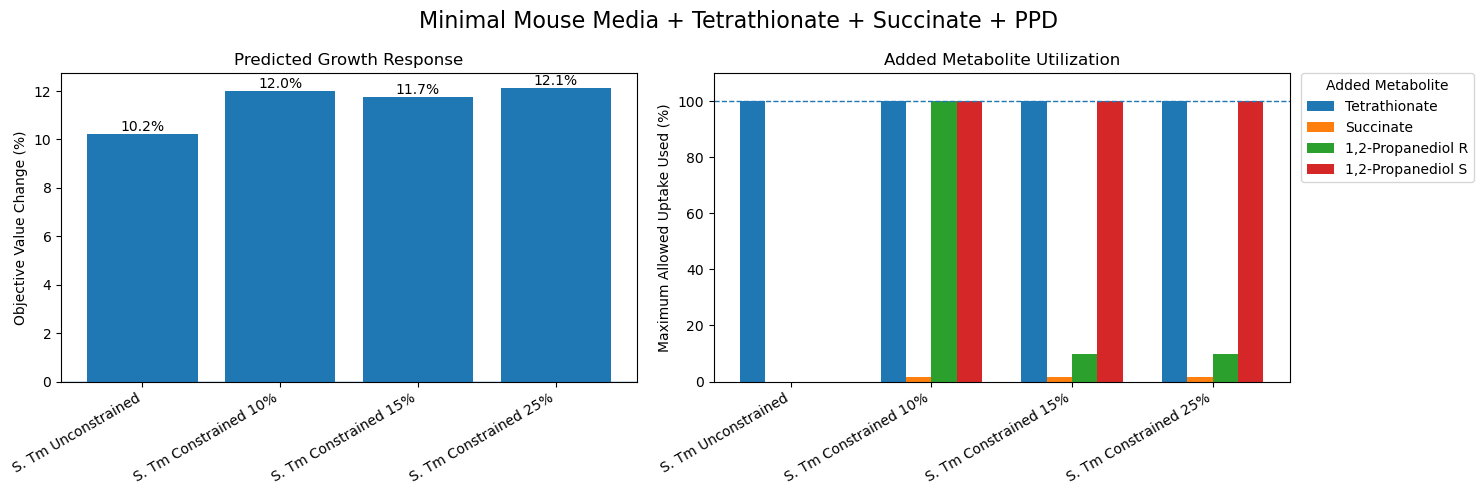

In [45]:
# ============================================================
# TETRATHIONATE + SUCCINATE + PPD
# ============================================================

condition = "Tet + Succ + PPD"

condition_df = (
    viz_df
    .filter(pl.col("Condition") == condition)
)


# ------------------------------------------------------------
# Growth
# ------------------------------------------------------------

growth_df_plot = (
    condition_df
    .select(
        "Model",
        "Objective Percent Change"
    )
    .unique()
)

growth_lookup = {
    row["Model"]: row["Objective Percent Change"]
    for row in growth_df_plot.iter_rows(named=True)
}

models_present = [
    model for model in model_order
    if model in growth_lookup
]

growth_values = [
    growth_lookup[model]
    for model in models_present
]


# ------------------------------------------------------------
# Tetrathionate
# ------------------------------------------------------------

tet_df = condition_df.filter(
    pl.col("Added Metabolite") == "Tetrathionate"
)

tet_lookup = {
    row["Model"]: row
    for row in tet_df.iter_rows(named=True)
}

tet_percent = [
    tet_lookup[model]["Percent of Uptake Bound Used"]
    for model in models_present
]


# ------------------------------------------------------------
# Succinate
# ------------------------------------------------------------

succ_df = condition_df.filter(
    pl.col("Added Metabolite") == "Succinate"
)

succ_lookup = {
    row["Model"]: row
    for row in succ_df.iter_rows(named=True)
}

succ_percent = [
    succ_lookup[model]["Percent of Uptake Bound Used"]
    for model in models_present
]


# ------------------------------------------------------------
# PPD R
# ------------------------------------------------------------

ppd_r_df = condition_df.filter(
    pl.col("Added Metabolite") == "1,2-Propanediol R"
)

ppd_r_lookup = {
    row["Model"]: row
    for row in ppd_r_df.iter_rows(named=True)
}

ppd_r_percent = [
    ppd_r_lookup[model]["Percent of Uptake Bound Used"]
    for model in models_present
]


# ------------------------------------------------------------
# PPD S
# ------------------------------------------------------------

ppd_s_df = condition_df.filter(
    pl.col("Added Metabolite") == "1,2-Propanediol S"
)

ppd_s_lookup = {
    row["Model"]: row
    for row in ppd_s_df.iter_rows(named=True)
}

ppd_s_percent = [
    ppd_s_lookup[model]["Percent of Uptake Bound Used"]
    for model in models_present
]


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

x = np.arange(len(models_present))
width = 0.18

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)


# Growth
bars = axes[0].bar(
    x,
    growth_values
)

axes[0].axhline(0, linewidth=1)

axes[0].set_xticks(x)

axes[0].set_xticklabels(
    models_present,
    rotation=30,
    ha="right"
)

axes[0].set_ylabel(
    "Objective Value Change (%)"
)

axes[0].set_title(
    "Predicted Growth Response"
)

for bar, value in zip(
    bars,
    growth_values
):

    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.1f}%",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )


# Utilization
axes[1].bar(
    x - 1.5 * width,
    tet_percent,
    width,
    label="Tetrathionate"
)

axes[1].bar(
    x - 0.5 * width,
    succ_percent,
    width,
    label="Succinate"
)

axes[1].bar(
    x + 0.5 * width,
    ppd_r_percent,
    width,
    label="1,2-Propanediol R"
)

axes[1].bar(
    x + 1.5 * width,
    ppd_s_percent,
    width,
    label="1,2-Propanediol S"
)

axes[1].axhline(
    100,
    linestyle="--",
    linewidth=1
)

axes[1].set_xticks(x)

axes[1].set_xticklabels(
    models_present,
    rotation=30,
    ha="right"
)

axes[1].set_ylabel(
    "Maximum Allowed Uptake Used (%)"
)

axes[1].set_ylim(
    0,
    110
)

axes[1].set_title(
    "Added Metabolite Utilization"
)

axes[1].legend(
    title="Added Metabolite",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0
)


fig.suptitle(
    "Minimal Mouse Media + Tetrathionate + Succinate + PPD",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    f"{plot_dir}/tet_succ_ppd_growth_and_utilization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

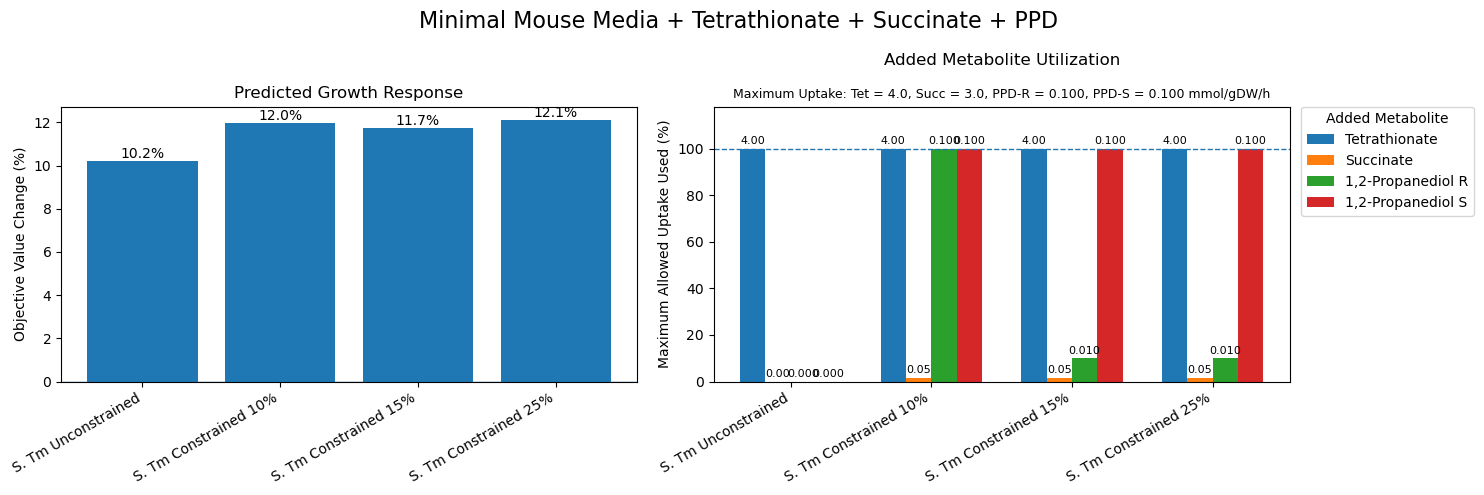

In [68]:
# ============================================================
# TETRATHIONATE + SUCCINATE + PPD
# ============================================================

condition = "Tet + Succ + PPD"

condition_df = (
    viz_df
    .filter(pl.col("Condition") == condition)
)


# ============================================================
# GROWTH RESPONSE
# ============================================================

growth_df_plot = (
    condition_df
    .select(
        "Model",
        "Objective Percent Change"
    )
    .unique()
)

growth_lookup = {
    row["Model"]: row["Objective Percent Change"]
    for row in growth_df_plot.iter_rows(named=True)
}

models_present = [
    model for model in model_order
    if model in growth_lookup
]

growth_values = [
    growth_lookup[model]
    for model in models_present
]


# ============================================================
# TETRATHIONATE
# ============================================================

tet_df = (
    condition_df
    .filter(
        pl.col("Added Metabolite") == "Tetrathionate"
    )
)

tet_lookup = {
    row["Model"]: row
    for row in tet_df.iter_rows(named=True)
}


# Percent of maximum tetrathionate uptake used
tet_percent = [
    tet_lookup[model]["Percent of Uptake Bound Used"]
    for model in models_present
]


# Actual tetrathionate uptake utilized
tet_flux = [
    tet_lookup[model]["Uptake Flux"]
    for model in models_present
]


# Maximum tetrathionate uptake allowed
tet_bound = (
    tet_df["Medium Uptake Bound"][0]
)


# ============================================================
# SUCCINATE
# ============================================================

succ_df = (
    condition_df
    .filter(
        pl.col("Added Metabolite") == "Succinate"
    )
)

succ_lookup = {
    row["Model"]: row
    for row in succ_df.iter_rows(named=True)
}


# Percent of maximum succinate uptake used
succ_percent = [
    succ_lookup[model]["Percent of Uptake Bound Used"]
    for model in models_present
]


# Actual succinate uptake utilized
succ_flux = [
    succ_lookup[model]["Uptake Flux"]
    for model in models_present
]


# Maximum succinate uptake allowed
succ_bound = (
    succ_df["Medium Uptake Bound"][0]
)


# ============================================================
# PPD R
# ============================================================

ppd_r_df = (
    condition_df
    .filter(
        pl.col("Added Metabolite") == "1,2-Propanediol R"
    )
)

ppd_r_lookup = {
    row["Model"]: row
    for row in ppd_r_df.iter_rows(named=True)
}


# Percent of maximum PPD-R uptake used
ppd_r_percent = [
    ppd_r_lookup[model]["Percent of Uptake Bound Used"]
    for model in models_present
]


# Actual PPD-R uptake utilized
ppd_r_flux = [
    ppd_r_lookup[model]["Uptake Flux"]
    for model in models_present
]


# Maximum PPD-R uptake allowed
ppd_r_bound = (
    ppd_r_df["Medium Uptake Bound"][0]
)


# ============================================================
# PPD S
# ============================================================

ppd_s_df = (
    condition_df
    .filter(
        pl.col("Added Metabolite") == "1,2-Propanediol S"
    )
)

ppd_s_lookup = {
    row["Model"]: row
    for row in ppd_s_df.iter_rows(named=True)
}


# Percent of maximum PPD-S uptake used
ppd_s_percent = [
    ppd_s_lookup[model]["Percent of Uptake Bound Used"]
    for model in models_present
]


# Actual PPD-S uptake utilized
ppd_s_flux = [
    ppd_s_lookup[model]["Uptake Flux"]
    for model in models_present
]


# Maximum PPD-S uptake allowed
ppd_s_bound = (
    ppd_s_df["Medium Uptake Bound"][0]
)


# ============================================================
# PLOT
# ============================================================

x = np.arange(len(models_present))
width = 0.18

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)


# ============================================================
# LEFT: GROWTH RESPONSE
# ============================================================

bars = axes[0].bar(
    x,
    growth_values
)

axes[0].axhline(
    0,
    linewidth=1
)

axes[0].set_xticks(x)

axes[0].set_xticklabels(
    models_present,
    rotation=30,
    ha="right"
)

axes[0].set_ylabel(
    "Objective Value Change (%)"
)

axes[0].set_title(
    "Predicted Growth Response"
)


# Objective percent change above each bar
for bar, value in zip(
    bars,
    growth_values
):

    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.1f}%",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )


# ============================================================
# RIGHT: METABOLITE UTILIZATION
# ============================================================

# Save bar objects so uptake values can be placed above them
tet_bars = axes[1].bar(
    x - 1.5 * width,
    tet_percent,
    width,
    label="Tetrathionate"
)

succ_bars = axes[1].bar(
    x - 0.5 * width,
    succ_percent,
    width,
    label="Succinate"
)

ppd_r_bars = axes[1].bar(
    x + 0.5 * width,
    ppd_r_percent,
    width,
    label="1,2-Propanediol R"
)

ppd_s_bars = axes[1].bar(
    x + 1.5 * width,
    ppd_s_percent,
    width,
    label="1,2-Propanediol S"
)


# 100% reference line
axes[1].axhline(
    100,
    linestyle="--",
    linewidth=1
)

axes[1].set_xticks(x)

axes[1].set_xticklabels(
    models_present,
    rotation=30,
    ha="right"
)

axes[1].set_ylabel(
    "Maximum Allowed Uptake Used (%)"
)


# Extra space for labels
axes[1].set_ylim(
    0,
    118
)


# Main title
axes[1].set_title(
    "Added Metabolite Utilization",
    pad=30
)


# Maximum metabolite available for uptake
axes[1].text(
    0.5,
    1.02,
    (
        f"Maximum Uptake: "
        f"Tet = {tet_bound:.1f}, "
        f"Succ = {succ_bound:.1f}, "
        f"PPD-R = {ppd_r_bound:.3f}, "
        f"PPD-S = {ppd_s_bound:.3f} mmol/gDW/h"
    ),
    transform=axes[1].transAxes,
    ha="center",
    va="bottom",
    fontsize=9
)


# ============================================================
# ACTUAL TETRATHIONATE UTILIZED
# ============================================================

for bar, percent, flux in zip(
    tet_bars,
    tet_percent,
    tet_flux
):

    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        percent + 1,
        f"{flux:.2f}",
        ha="center",
        va="bottom",
        fontsize=8
    )


# ============================================================
# ACTUAL SUCCINATE UTILIZED
# ============================================================

for bar, percent, flux in zip(
    succ_bars,
    succ_percent,
    succ_flux
):

    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        percent + 1,
        f"{flux:.2f}",
        ha="center",
        va="bottom",
        fontsize=8
    )


# ============================================================
# ACTUAL PPD-R UTILIZED
# ============================================================

for bar, percent, flux in zip(
    ppd_r_bars,
    ppd_r_percent,
    ppd_r_flux
):

    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        percent + 1,
        f"{flux:.3f}",
        ha="center",
        va="bottom",
        fontsize=8
    )


# ============================================================
# ACTUAL PPD-S UTILIZED
# ============================================================

for bar, percent, flux in zip(
    ppd_s_bars,
    ppd_s_percent,
    ppd_s_flux
):

    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        percent + 1,
        f"{flux:.3f}",
        ha="center",
        va="bottom",
        fontsize=8
    )


# Legend outside plot
axes[1].legend(
    title="Added Metabolite",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0
)


# ============================================================
# FIGURE TITLE
# ============================================================

fig.suptitle(
    "Minimal Mouse Media + Tetrathionate + Succinate + PPD",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    f"{plot_dir}/tet_succ_ppd_growth_and_utilization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

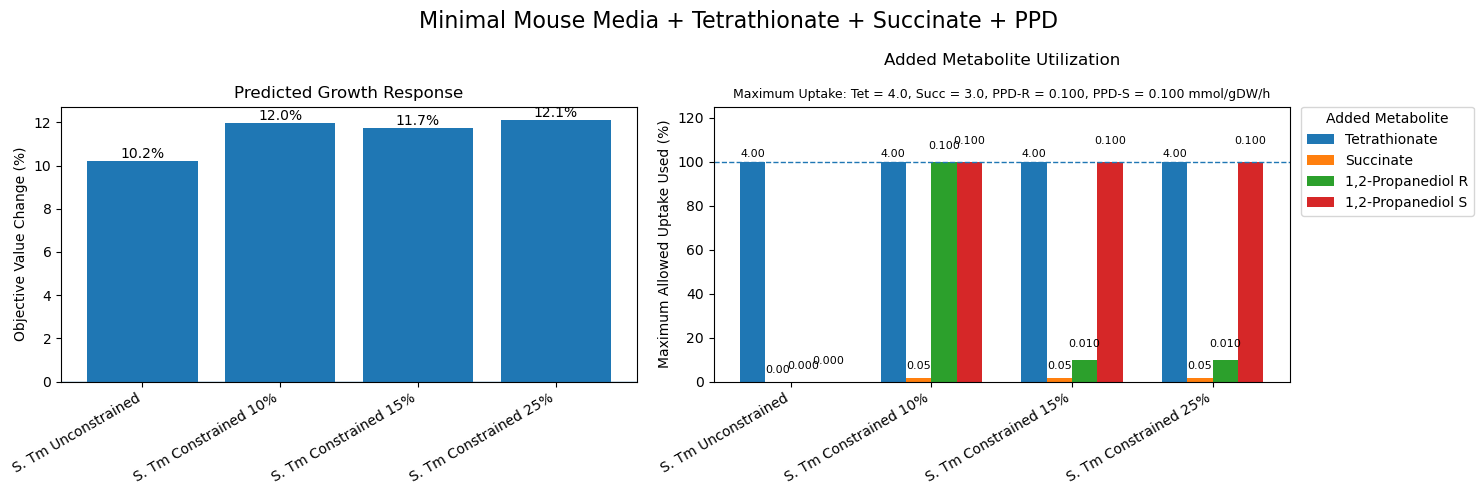

In [70]:
# ============================================================
# TETRATHIONATE + SUCCINATE + PPD
# ============================================================

condition = "Tet + Succ + PPD"

condition_df = (
    viz_df
    .filter(pl.col("Condition") == condition)
)


# ============================================================
# GROWTH RESPONSE
# ============================================================

growth_df_plot = (
    condition_df
    .select(
        "Model",
        "Objective Percent Change"
    )
    .unique()
)

growth_lookup = {
    row["Model"]: row["Objective Percent Change"]
    for row in growth_df_plot.iter_rows(named=True)
}

models_present = [
    model for model in model_order
    if model in growth_lookup
]

growth_values = [
    growth_lookup[model]
    for model in models_present
]


# ============================================================
# TETRATHIONATE
# ============================================================

tet_df = (
    condition_df
    .filter(
        pl.col("Added Metabolite") == "Tetrathionate"
    )
)

tet_lookup = {
    row["Model"]: row
    for row in tet_df.iter_rows(named=True)
}

# Percent of maximum tetrathionate uptake used
tet_percent = [
    tet_lookup[model]["Percent of Uptake Bound Used"]
    for model in models_present
]

# Actual tetrathionate uptake utilized
tet_flux = [
    tet_lookup[model]["Uptake Flux"]
    for model in models_present
]

# Maximum tetrathionate uptake allowed
tet_bound = (
    tet_df["Medium Uptake Bound"][0]
)


# ============================================================
# SUCCINATE
# ============================================================

succ_df = (
    condition_df
    .filter(
        pl.col("Added Metabolite") == "Succinate"
    )
)

succ_lookup = {
    row["Model"]: row
    for row in succ_df.iter_rows(named=True)
}

# Percent of maximum succinate uptake used
succ_percent = [
    succ_lookup[model]["Percent of Uptake Bound Used"]
    for model in models_present
]

# Actual succinate uptake utilized
succ_flux = [
    succ_lookup[model]["Uptake Flux"]
    for model in models_present
]

# Maximum succinate uptake allowed
succ_bound = (
    succ_df["Medium Uptake Bound"][0]
)


# ============================================================
# PPD R
# ============================================================

ppd_r_df = (
    condition_df
    .filter(
        pl.col("Added Metabolite") == "1,2-Propanediol R"
    )
)

ppd_r_lookup = {
    row["Model"]: row
    for row in ppd_r_df.iter_rows(named=True)
}

# Percent of maximum PPD-R uptake used
ppd_r_percent = [
    ppd_r_lookup[model]["Percent of Uptake Bound Used"]
    for model in models_present
]

# Actual PPD-R uptake utilized
ppd_r_flux = [
    ppd_r_lookup[model]["Uptake Flux"]
    for model in models_present
]

# Maximum PPD-R uptake allowed
ppd_r_bound = (
    ppd_r_df["Medium Uptake Bound"][0]
)


# ============================================================
# PPD S
# ============================================================

ppd_s_df = (
    condition_df
    .filter(
        pl.col("Added Metabolite") == "1,2-Propanediol S"
    )
)

ppd_s_lookup = {
    row["Model"]: row
    for row in ppd_s_df.iter_rows(named=True)
}

# Percent of maximum PPD-S uptake used
ppd_s_percent = [
    ppd_s_lookup[model]["Percent of Uptake Bound Used"]
    for model in models_present
]

# Actual PPD-S uptake utilized
ppd_s_flux = [
    ppd_s_lookup[model]["Uptake Flux"]
    for model in models_present
]

# Maximum PPD-S uptake allowed
ppd_s_bound = (
    ppd_s_df["Medium Uptake Bound"][0]
)


# ============================================================
# PLOT
# ============================================================

x = np.arange(len(models_present))
width = 0.18

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)


# ============================================================
# LEFT: GROWTH RESPONSE
# ============================================================

bars = axes[0].bar(
    x,
    growth_values
)

axes[0].axhline(
    0,
    linewidth=1
)

axes[0].set_xticks(x)

axes[0].set_xticklabels(
    models_present,
    rotation=30,
    ha="right"
)

axes[0].set_ylabel(
    "Objective Value Change (%)"
)

axes[0].set_title(
    "Predicted Growth Response"
)

# Objective percent change above each bar
for bar, value in zip(
    bars,
    growth_values
):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.1f}%",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )


# ============================================================
# RIGHT: METABOLITE UTILIZATION
# ============================================================

# Save bar objects so uptake values can be placed above them
tet_bars = axes[1].bar(
    x - 1.5 * width,
    tet_percent,
    width,
    label="Tetrathionate"
)

succ_bars = axes[1].bar(
    x - 0.5 * width,
    succ_percent,
    width,
    label="Succinate"
)

ppd_r_bars = axes[1].bar(
    x + 0.5 * width,
    ppd_r_percent,
    width,
    label="1,2-Propanediol R"
)

ppd_s_bars = axes[1].bar(
    x + 1.5 * width,
    ppd_s_percent,
    width,
    label="1,2-Propanediol S"
)

# 100% reference line
axes[1].axhline(
    100,
    linestyle="--",
    linewidth=1
)

axes[1].set_xticks(x)

axes[1].set_xticklabels(
    models_present,
    rotation=30,
    ha="right"
)

axes[1].set_ylabel(
    "Maximum Allowed Uptake Used (%)"
)

# Extra space for staggered labels
axes[1].set_ylim(
    0,
    125
)

# Main title
axes[1].set_title(
    "Added Metabolite Utilization",
    pad=30
)

# Maximum metabolite available for uptake
axes[1].text(
    0.5,
    1.02,
    (
        f"Maximum Uptake: "
        f"Tet = {tet_bound:.1f}, "
        f"Succ = {succ_bound:.1f}, "
        f"PPD-R = {ppd_r_bound:.3f}, "
        f"PPD-S = {ppd_s_bound:.3f} mmol/gDW/h"
    ),
    transform=axes[1].transAxes,
    ha="center",
    va="bottom",
    fontsize=9
)


# ============================================================
# ACTUAL TETRATHIONATE UTILIZED
# ============================================================

for bar, percent, flux in zip(
    tet_bars,
    tet_percent,
    tet_flux
):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        percent + 1,
        f"{flux:.2f}",
        ha="center",
        va="bottom",
        fontsize=8
    )


# ============================================================
# ACTUAL SUCCINATE UTILIZED
# ============================================================

for bar, percent, flux in zip(
    succ_bars,
    succ_percent,
    succ_flux
):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        percent + 3,
        f"{flux:.2f}",
        ha="center",
        va="bottom",
        fontsize=8
    )


# ============================================================
# ACTUAL PPD-R UTILIZED
# ============================================================

for bar, percent, flux in zip(
    ppd_r_bars,
    ppd_r_percent,
    ppd_r_flux
):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        percent + 5,
        f"{flux:.3f}",
        ha="center",
        va="bottom",
        fontsize=8
    )


# ============================================================
# ACTUAL PPD-S UTILIZED
# ============================================================

for bar, percent, flux in zip(
    ppd_s_bars,
    ppd_s_percent,
    ppd_s_flux
):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        percent + 7,
        f"{flux:.3f}",
        ha="center",
        va="bottom",
        fontsize=8
    )


# Legend outside plot
axes[1].legend(
    title="Added Metabolite",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0
)


# ============================================================
# FIGURE TITLE
# ============================================================

fig.suptitle(
    "Minimal Mouse Media + Tetrathionate + Succinate + PPD",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    f"{plot_dir}/tet_succ_ppd_growth_and_utilization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Option 3
How does metabolite utilization relate to growth advantage by adding that metaboloite? 
x axis: percent of metabolite used
y axis: growth rate percent change
scatter plot, each point is a model, 

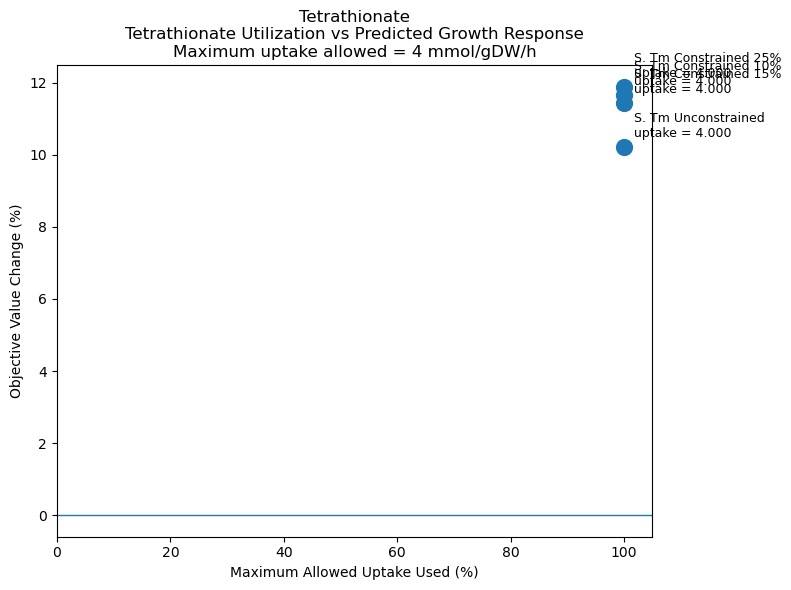

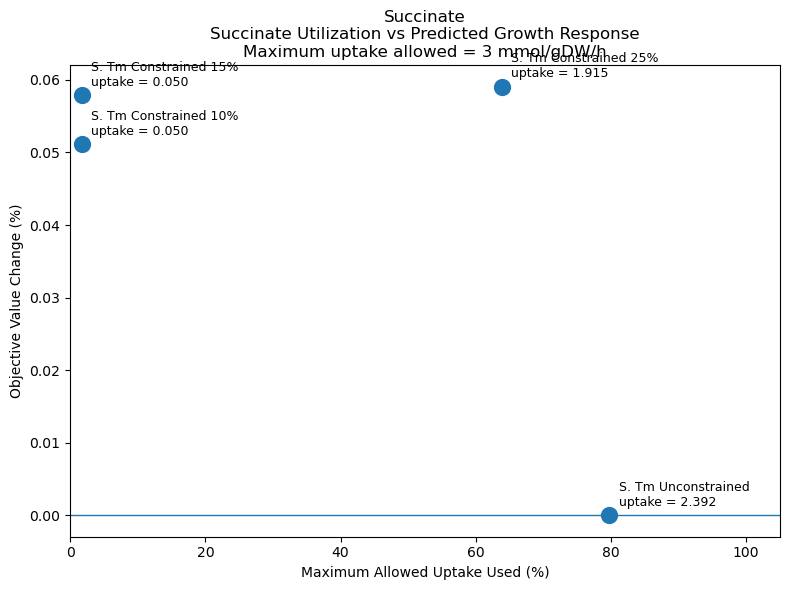

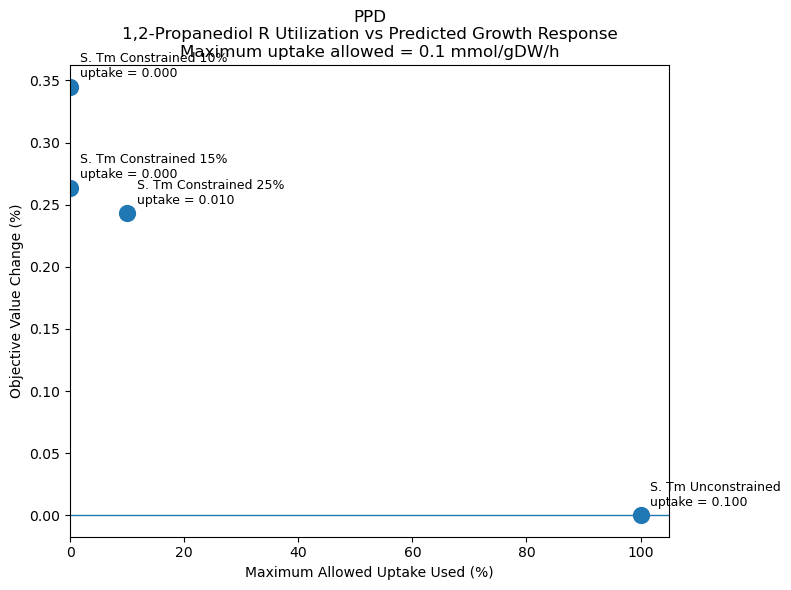

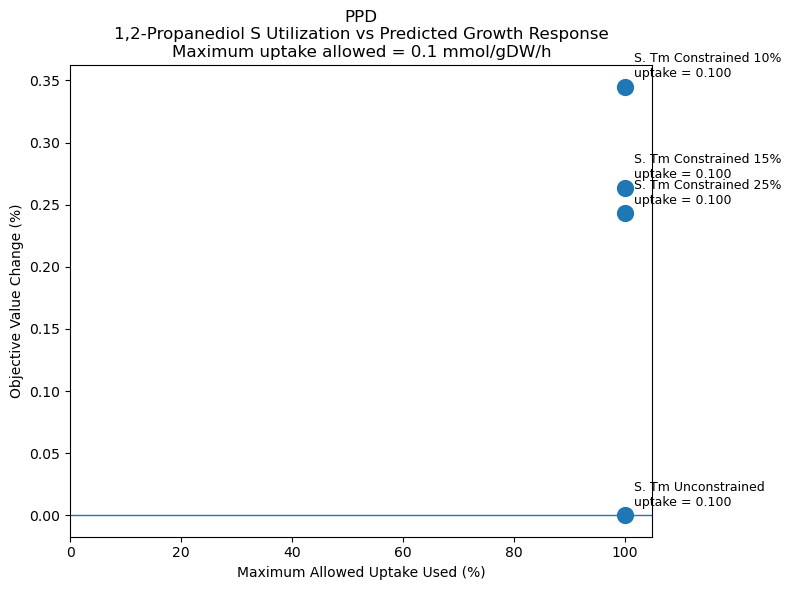

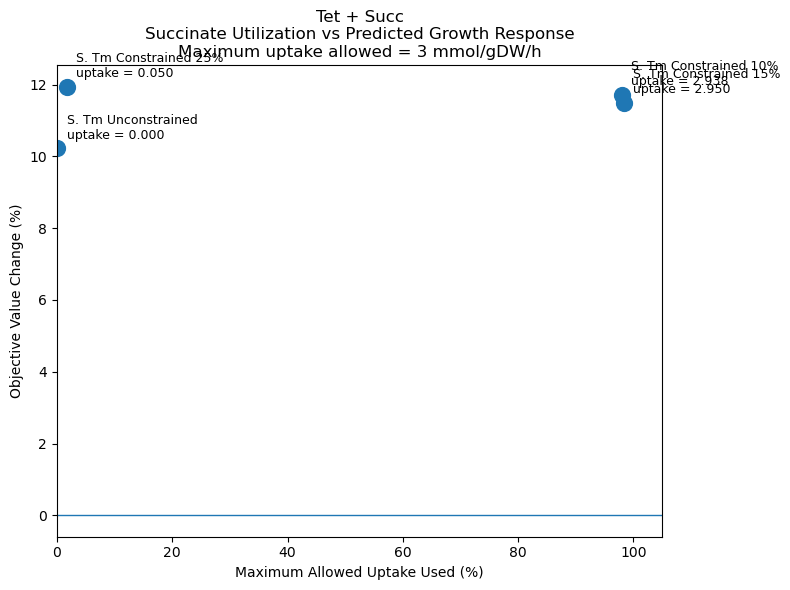

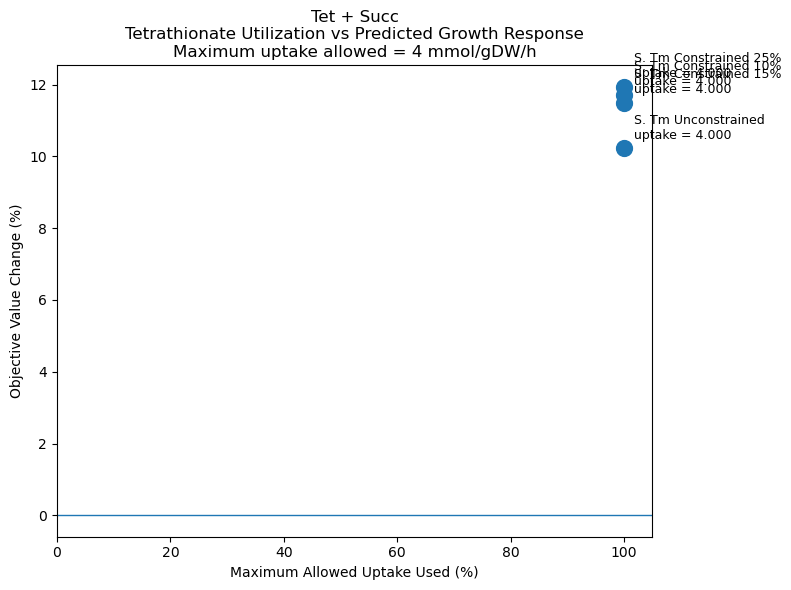

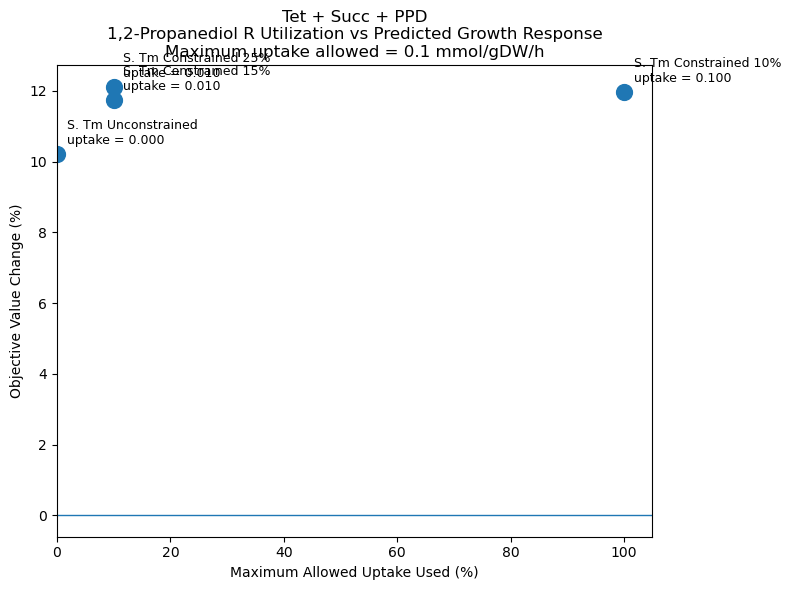

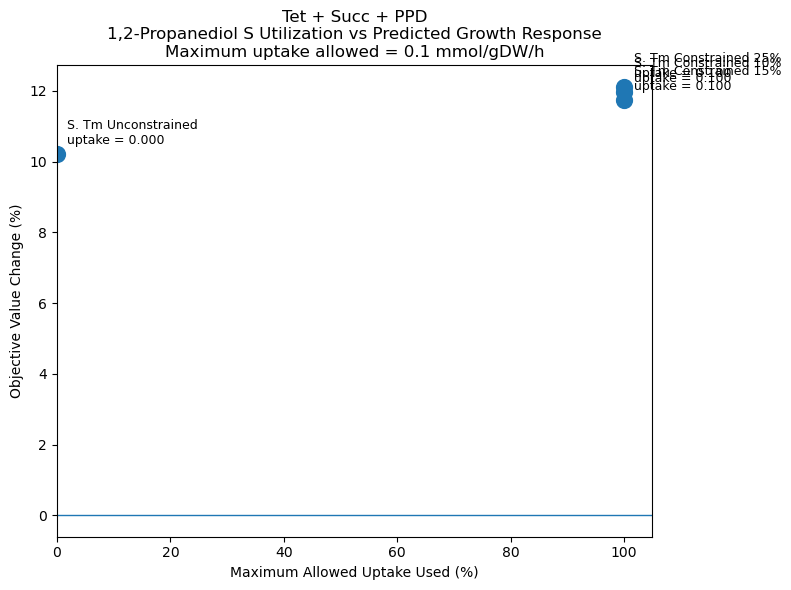

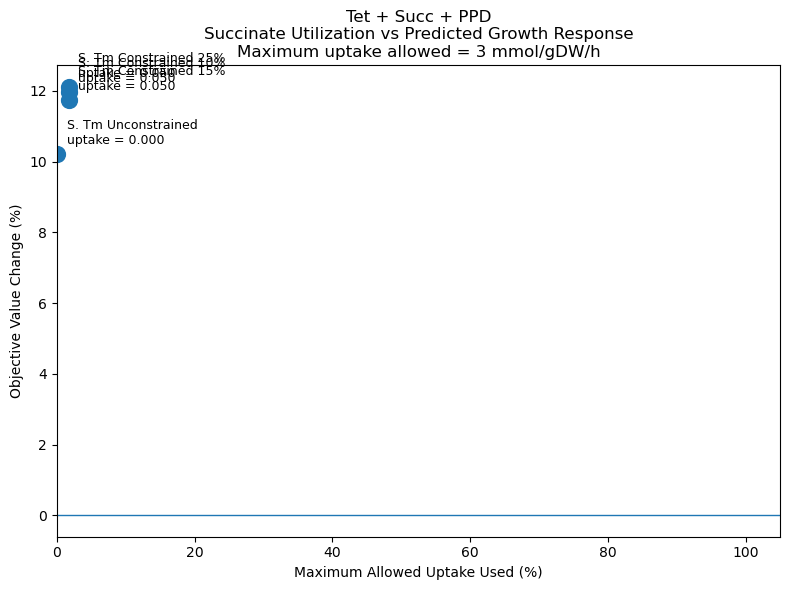

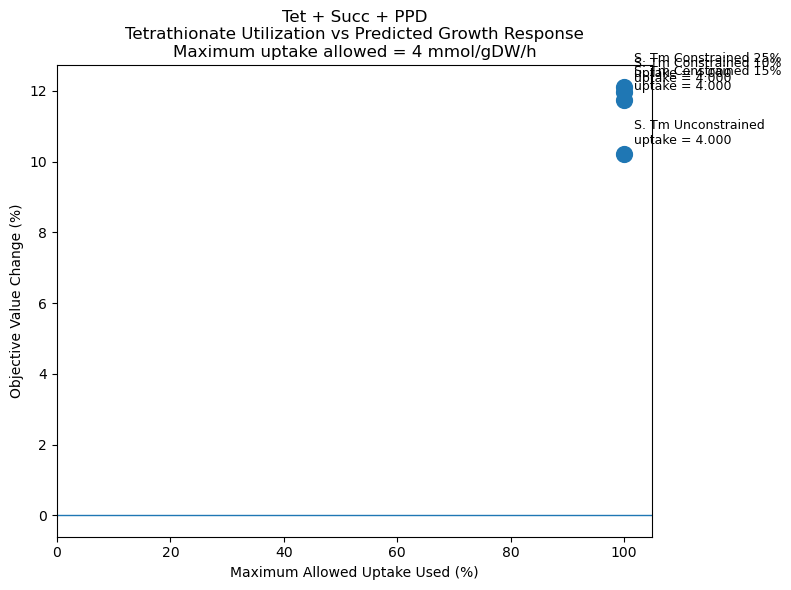

In [71]:
condition_order = [
    "Tetrathionate",
    "Succinate",
    "PPD",
    "Tet + Succ",
    "Tet + Succ + PPD"
]


for condition in condition_order:

    condition_df = (
        viz_df
        .filter(
            pl.col("Condition") == condition
        )
    )


    metabolites = (
        condition_df[
            "Added Metabolite"
        ]
        .unique()
        .sort()
        .to_list()
    )


    for metabolite in metabolites:

        plot_df = (
            condition_df

            .filter(
                pl.col("Added Metabolite")
                == metabolite
            )
        )


        utilization = (
            plot_df[
                "Percent of Uptake Bound Used"
            ]
            .to_list()
        )


        growth_change = (
            plot_df[
                "Objective Percent Change"
            ]
            .to_list()
        )


        models_plot = (
            plot_df[
                "Model"
            ]
            .to_list()
        )


        uptake_flux = (
            plot_df[
                "Uptake Flux"
            ]
            .to_list()
        )


        uptake_bound = (
            plot_df[
                "Medium Uptake Bound"
            ][0]
        )


        # --------------------------------
        # Scatter plot
        # --------------------------------

        plt.figure(
            figsize=(8, 6)
        )


        plt.scatter(
            utilization,
            growth_change,
            s=130
        )


        plt.axhline(
            0,
            linewidth=1
        )


        # Label each model
        for (
            x_value,
            y_value,
            model,
            flux
        ) in zip(
            utilization,
            growth_change,
            models_plot,
            uptake_flux
        ):

            plt.annotate(
                f"{model}\n"
                f"uptake = {flux:.3f}",
                (
                    x_value,
                    y_value
                ),
                xytext=(7, 7),
                textcoords="offset points",
                fontsize=9
            )


        plt.xlabel(
            "Maximum Allowed Uptake Used (%)"
        )

        plt.ylabel(
            "Objective Value Change (%)"
        )


        plt.xlim(
            0,
            105
        )


        plt.title(
            f"{condition}\n"
            f"{metabolite} Utilization vs Predicted Growth Response\n"
            f"Maximum uptake allowed = "
            f"{uptake_bound:g} mmol/gDW/h"
        )


        plt.tight_layout()


        condition_name = (
            condition
            .lower()
            .replace(" ", "_")
            .replace("+", "and")
        )


        metabolite_name = (
            metabolite
            .lower()
            .replace(" ", "_")
            .replace(",", "")
            .replace("-", "_")
        )


        plt.savefig(
            f"{plot_dir}/"
            f"{condition_name}_"
            f"{metabolite_name}_"
            f"uptake_vs_growth.png",
            dpi=300,
            bbox_inches="tight"
        )


        plt.show()

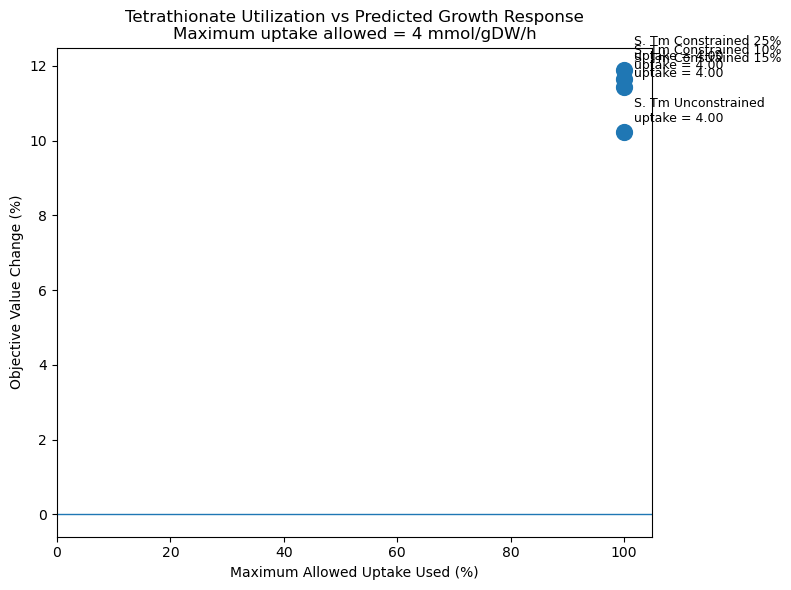

In [72]:
# ============================================================
# TETRATHIONATE
# ============================================================

condition = "Tetrathionate"
metabolite = "Tetrathionate"

plot_df = (
    viz_df
    .filter(
        (pl.col("Condition") == condition)
        &
        (pl.col("Added Metabolite") == metabolite)
    )
)


# ------------------------------------------------------------
# Data
# ------------------------------------------------------------

utilization = (
    plot_df["Percent of Uptake Bound Used"]
    .to_list()
)

growth_change = (
    plot_df["Objective Percent Change"]
    .to_list()
)

models_plot = (
    plot_df["Model"]
    .to_list()
)

uptake_flux = (
    plot_df["Uptake Flux"]
    .to_list()
)

uptake_bound = (
    plot_df["Medium Uptake Bound"][0]
)


# ------------------------------------------------------------
# Scatter plot
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 6)
)

plt.scatter(
    utilization,
    growth_change,
    s=130
)

plt.axhline(
    0,
    linewidth=1
)


# Label each model
for (
    x_value,
    y_value,
    model,
    flux
) in zip(
    utilization,
    growth_change,
    models_plot,
    uptake_flux
):

    plt.annotate(
        f"{model}\n"
        f"uptake = {flux:.2f}",
        (
            x_value,
            y_value
        ),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=9
    )


plt.xlabel(
    "Maximum Allowed Uptake Used (%)"
)

plt.ylabel(
    "Objective Value Change (%)"
)

plt.xlim(
    0,
    105
)

plt.title(
    f"Tetrathionate Utilization vs Predicted Growth Response\n"
    f"Maximum uptake allowed = "
    f"{uptake_bound:g} mmol/gDW/h"
)

plt.tight_layout()

plt.savefig(
    f"{plot_dir}/tetrathionate_uptake_vs_growth.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

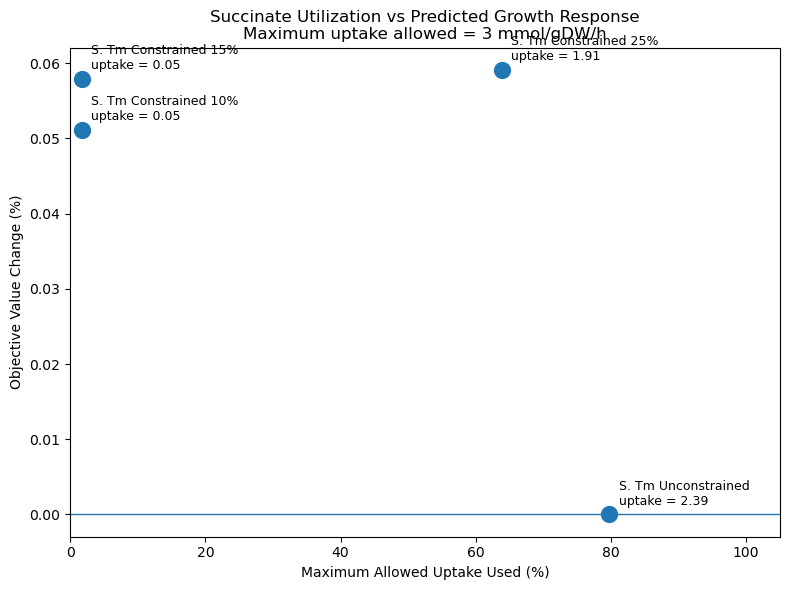

In [73]:
# ============================================================
# SUCCINATE
# ============================================================

condition = "Succinate"
metabolite = "Succinate"

plot_df = (
    viz_df
    .filter(
        (pl.col("Condition") == condition)
        &
        (pl.col("Added Metabolite") == metabolite)
    )
)


# ------------------------------------------------------------
# Data
# ------------------------------------------------------------

utilization = (
    plot_df["Percent of Uptake Bound Used"]
    .to_list()
)

growth_change = (
    plot_df["Objective Percent Change"]
    .to_list()
)

models_plot = (
    plot_df["Model"]
    .to_list()
)

uptake_flux = (
    plot_df["Uptake Flux"]
    .to_list()
)

uptake_bound = (
    plot_df["Medium Uptake Bound"][0]
)


# ------------------------------------------------------------
# Scatter plot
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 6)
)

plt.scatter(
    utilization,
    growth_change,
    s=130
)

plt.axhline(
    0,
    linewidth=1
)


for (
    x_value,
    y_value,
    model,
    flux
) in zip(
    utilization,
    growth_change,
    models_plot,
    uptake_flux
):

    plt.annotate(
        f"{model}\n"
        f"uptake = {flux:.2f}",
        (
            x_value,
            y_value
        ),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=9
    )


plt.xlabel(
    "Maximum Allowed Uptake Used (%)"
)

plt.ylabel(
    "Objective Value Change (%)"
)

plt.xlim(
    0,
    105
)

plt.title(
    f"Succinate Utilization vs Predicted Growth Response\n"
    f"Maximum uptake allowed = "
    f"{uptake_bound:g} mmol/gDW/h"
)

plt.tight_layout()

plt.savefig(
    f"{plot_dir}/succinate_uptake_vs_growth.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## comparing metbaolite utilization across medias

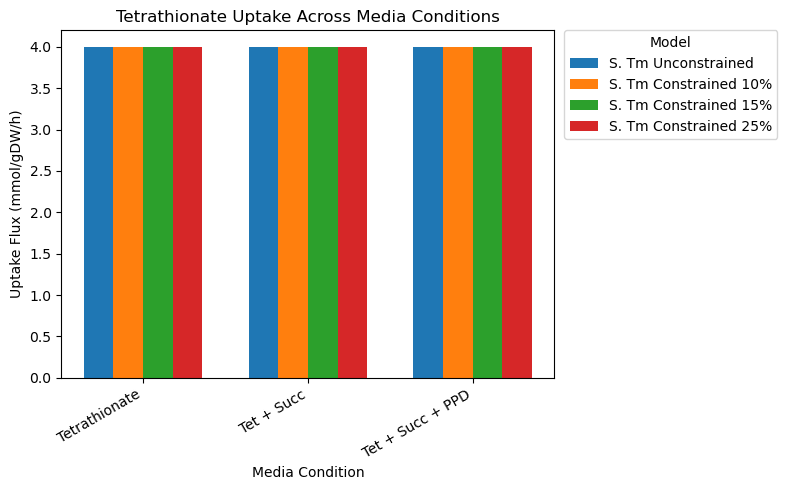

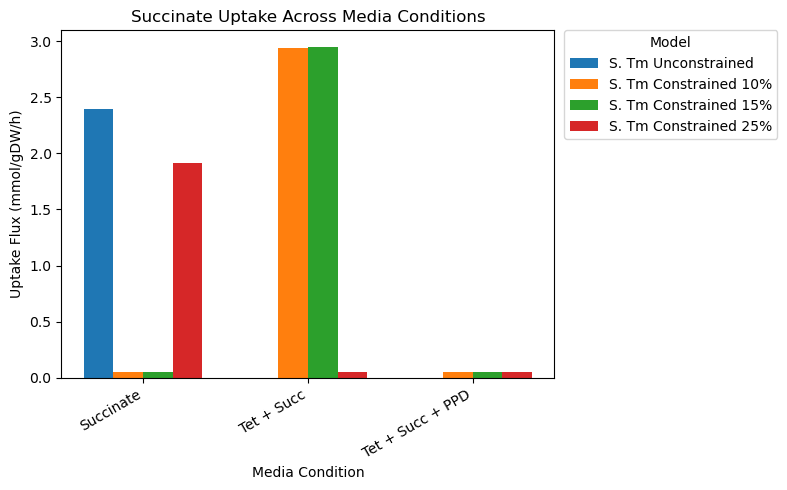

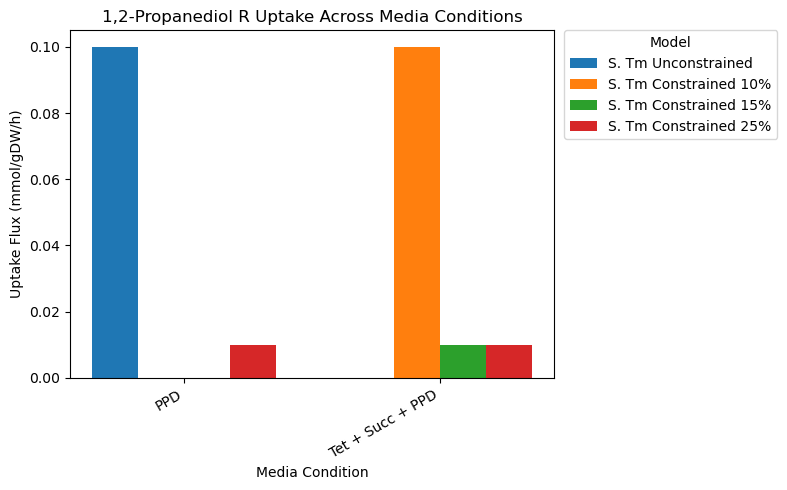

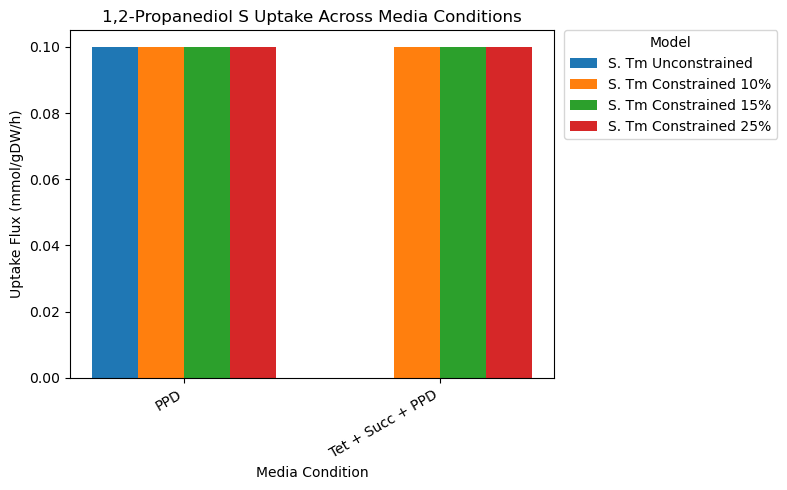

In [76]:
import numpy as np
import matplotlib.pyplot as plt

metabolites = [
    "Tetrathionate",
    "Succinate",
    "1,2-Propanediol R",
    "1,2-Propanediol S"
]

models = [
    "stm_unconstrained",
    "mixed_stm1090",
    "mixed_stm1585",
    "mixed_stm2575"
]

condition_order = {
    "Tetrathionate": [
        "Tetrathionate",
        "Tet + Succ",
        "Tet + Succ + PPD"
    ],
    "Succinate": [
        "Succinate",
        "Tet + Succ",
        "Tet + Succ + PPD"
    ],
    "1,2-Propanediol R": [
        "PPD",
        "Tet + Succ + PPD"
    ],
    "1,2-Propanediol S": [
        "PPD",
        "Tet + Succ + PPD"
    ]
}


for metabolite in metabolites:

    metabolite_df = uptake_comparison_df.filter(
        pl.col("Added Metabolite") == metabolite
    )

    conditions = condition_order[metabolite]

    x = np.arange(len(conditions))
    width = 0.18

    plt.figure(
        figsize=(8, 5)
    )


    for i, model in enumerate(models):

        model_df = metabolite_df.filter(
            pl.col("Model") == model
        )

        uptake_values = []

        for condition in conditions:

            value = (
                model_df
                .filter(
                    pl.col("Condition") == condition
                )
                ["Uptake Flux"]
                .to_list()
            )

            uptake_values.append(
                value[0] if value else 0
            )


        plt.bar(
            x + (i - 1.5) * width,
            uptake_values,
            width,
            label=model_labels[model]
        )


    plt.xticks(
        x,
        conditions,
        rotation=30,
        ha="right"
    )

    plt.ylabel(
        "Uptake Flux (mmol/gDW/h)"
    )

    plt.xlabel(
        "Media Condition"
    )

    plt.title(
        f"{metabolite} Uptake Across Media Conditions"
    )


    # Legend outside plot
    plt.legend(
        title="Model",
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        borderaxespad=0
    )


    plt.tight_layout()

    plt.show()